# Sites fédéraux recensés au FCSI et gouvernance territoriale autochtone : le rôle du Framework Agreement on First Nation Land Management

**Tran Nguyen Quoc-Long — Projet supervisé, M. Sc. finance, HEC Montréal**

Ce carnet construit l'échantillon et produit les tableaux, les figures et les tests du rapport. Il croise deux sources : l'Inventaire des sites contaminés fédéraux (FCSI, *Federal Contaminated Sites Inventory*), version 2023, et la liste des Premières Nations signataires de l'Accord-cadre relatif à la gestion des terres des Premières Nations (FNLM, *Framework Agreement on First Nation Land Management*), tenue par le Centre de ressources du Conseil consultatif des terres (LABRC) et prise dans son état de mars 2026.

Les titres de section renvoient entre parenthèses aux sections, tableaux et figures du rapport. Dans le texte, « section » seule désigne une section du carnet ; un renvoi au rapport le précise toujours. Les numéros de tableaux et de figures sont ceux du rapport.

Chaque cellule de code est suivie d'une explication du code puis, lorsqu'elle produit un résultat, de son interprétation. Les chiffres cités sont ceux des sorties enregistrées, et les écarts de probabilité sont exprimés en points de pourcentage (« points »). Le carnet s'exécute de haut en bas, depuis le dossier qui contient le fichier `.dta` du FCSI. Plusieurs assertions arrêtent l'exécution si un effectif diffère de celui que cite le rapport.

# Partie 1 — Données et construction de l'échantillon

## 1.1 Préparation, outils d'affichage et listes de colonnes

### Importation des paquets

In [1]:
import re, unicodedata
from pathlib import Path
from IPython.display import HTML, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats

### Explication du code

Cette cellule importe les bibliothèques utilisées dans tout le carnet. `re` et `unicodedata` normalisent les noms de bandes avant l'appariement. `pandas` et `numpy` manipulent les données. `statsmodels` estime les modèles de probabilité linéaire, probit et logit avec erreurs-types regroupées, et `scipy.stats` calcule la valeur p de l'extension temporelle (section 4.17). `matplotlib` produit les figures du rapport, tandis que `HTML` et `display` affichent les tableaux mis en forme.

### Importation des données

In [2]:
CHEMIN_FCSI = Path("GovofCanada_FCSI_AllProvinces_CombinedData_2023.dta")

fcsi_original = pd.read_stata(CHEMIN_FCSI)
nombre_observations, nombre_variables = fcsi_original.shape

print(f"Observations : {nombre_observations:,} | Variables : {nombre_variables}")

Observations : 197,025 | Variables : 44


### Explication du code

Le fichier Stata du FCSI (version 2023) est chargé sans modification dans `fcsi_original`. Le chemin est relatif : le carnet doit être lancé depuis le dossier du projet, où se trouve le fichier `.dta`.

### Interprétation

Le fichier brut compte 197 025 lignes et 44 variables. Chaque ligne décrit en principe un site pour un exercice financier, si bien qu'un même site apparaît sur plusieurs lignes. Certains couples site-exercice sont toutefois répétés. La section 1.2 retire ces doublons, puis ramène le panel à une ligne par site.

### Fonctions utilitaires

In [3]:

def nettoyer_nom(texte):

    texte = unicodedata.normalize("NFKD", str(texte))
    texte = "".join(c for c in texte if not unicodedata.combining(c))
    texte = texte.replace("'", "").replace("’", "").replace("‘", "").replace("`", "")
    texte = texte.lower().replace("&", " and ")
    return " ".join(re.findall(r"[a-z0-9]+", texte))

assert nettoyer_nom("Aq’am") == "aqam"
assert nettoyer_nom("Tsleil-Waututh") == "tsleil waututh"

def filtres_groupes(table_sites):

    return {
        "Réserve + FNLM": table_sites["reserve_lma"].eq(1),
        "Réserve sans FNLM": table_sites["reserve_non_lma"].eq(1),
        "Hors réserve": table_sites["est_reserve"].eq(0),
    }

STYLE_AFFICHAGE = """
<style>
  .tableau-fnlm {border-collapse: collapse; font-size: 13px; margin: 8px 0 18px 0;}
  .tableau-fnlm th {background: #1F4E78; color: white; padding: 7px 10px; text-align: center;}
  .tableau-fnlm td {padding: 6px 10px; text-align: center; border-bottom: 1px solid #D9E2F3;}
  .tableau-fnlm tbody tr:nth-child(even) {background: #EAF2F8;}
  .titre-tableau-fnlm {font-size: 15px; font-weight: 700; color: #1F4E78; margin-top: 8px;}
</style>
"""

def montrer_tableau(table, formats=None, titre=None, colonnes=None):
    if colonnes:
        table_affichee = table.rename(columns=colonnes)[list(colonnes.values())].copy()
    else:
        table_affichee = table.copy()
    for colonne in table_affichee.columns:
        if colonne in (formats or {}):
            format_case = formats[colonne]
        elif pd.api.types.is_float_dtype(table_affichee[colonne]):
            format_case = "{:.4f}"
        elif pd.api.types.is_integer_dtype(table_affichee[colonne]):
            format_case = "{:,}"
        else:
            continue
        table_affichee[colonne] = table_affichee[colonne].map(
            lambda v, f=format_case: "—" if pd.isna(v) else f.format(v)
        )
    bloc_titre = f'<div class="titre-tableau-fnlm">{titre}</div>' if titre else ""
    display(HTML(
        STYLE_AFFICHAGE
        + bloc_titre
        + table_affichee.to_html(index=False, border=0, classes="tableau-fnlm", escape=False)
    ))

### Explication du code

`nettoyer_nom` ramène deux graphies d'un même nom de bande à une forme commune. Elle retire les accents par décomposition Unicode, supprime les apostrophes sans les remplacer, remplace « & » par « and », met le texte en minuscules et ne garde que les suites de lettres et de chiffres, séparées par une espace. Un tiret devient donc une espace, alors qu'une apostrophe disparaît. Les deux assertions vérifient ces deux cas sur des noms réels : « Aq’am » devient « aqam » et « Tsleil-Waututh » devient « tsleil waututh ».

`filtres_groupes` renvoie les trois masques de catégories : réserve FNLM, réserve sans FNLM et hors réserve. Les tableaux et figures qui comparent les trois catégories passent par cette fonction, de sorte que chaque catégorie désigne partout les mêmes sites.

`montrer_tableau` affiche un tableau avec un style HTML commun. Le paramètre `colonnes`, un dictionnaire `{nom d'origine: libellé}`, renomme et ordonne les colonnes. Sans format précisé, les réels ont quatre décimales, les entiers un séparateur de milliers, et les valeurs manquantes s'affichent « — ».

### Listes de colonnes du FCSI

In [4]:
COLONNES_DEPENSES = [
    "totalassessmentexpenditure", "totalremediationexpenditure",
    "totalcaremaintenanceexpenditure", "totalmonitoringexpenditure",
]
COLONNES_QUANTITES = [
    "actualcubicmetersremediated", "actualhectaresremediated", "actualtonsremediated",
]
CLASSES_ANALYSEES = [
    "High Priority for Action", "Medium Priority for Action",
    "Low Priority for Action", "Not a Priority for Action",
]
CHAMPS_FIXES_SITE = [
    "sitename", "sitestatus", "class", "mediumcontaminants",
    "reportingorganization", "province", "involvement",
]
COLONNES_FCSI_NECESSAIRES = {
    "federalsiteidentifier", "fiscalyear", "closed", "higheststepcompleted",
    *CHAMPS_FIXES_SITE, *COLONNES_DEPENSES, *COLONNES_QUANTITES,
}

### Explication du code

Cette cellule déclare les colonnes du FCSI utilisées plus loin : les quatre postes de dépenses, les trois quantités remédiées, les quatre classes de priorité analysées et les champs descriptifs (`CHAMPS_FIXES_SITE`) qui doivent être identiques entre les lignes répétées d'un même couple site-exercice. `COLONNES_FCSI_NECESSAIRES` réunit ces listes ; la section 1.2 s'en sert pour vérifier, dès le chargement, qu'aucune colonne ne manque. Les champs de population, de coordonnées et de superficie, employés seulement dans la partie 4, n'y figurent pas. Seul le champ de population à un kilomètre est contrôlé à part (section 4.7).

L'ordre de `CLASSES_ANALYSEES` compte. Les trois premières classes (haute, moyenne et basse priorité) donnent la valeur 1 à la priorité d'action, et la quatrième, « Not a Priority for Action », la valeur 0 (section 1.5).

## 1.2 Du panel FCSI à une base de sites  *(rapport 3.1)*

### Doublons site-exercice

In [5]:
def retirer_doublons_annuels(df):
    cle = ["federalsiteidentifier", "fiscalyear"]
    doublons = df[df.duplicated(cle, keep=False)]
    for colonne in CHAMPS_FIXES_SITE:
        conflits = doublons.groupby(cle, dropna=False)[colonne].nunique(dropna=False).gt(1).sum()
        if conflits:
            raise AssertionError(f"{conflits} doublon(s) divergent pour {colonne}.")

    propre = df.groupby(cle, dropna=False, sort=False).tail(1).copy().set_index(cle)
    numeriques_max = ["higheststepcompleted"] + COLONNES_DEPENSES + COLONNES_QUANTITES
    propre[numeriques_max] = (
        df.groupby(cle, dropna=False, sort=False)[numeriques_max].max()
        .reindex(propre.index).astype(float)
    )
    propre["closed"] = (
        df.groupby(cle, dropna=False, sort=False)["closed"]
        .agg(lambda v: "True" if v.eq("True").any() else ("False" if v.eq("False").any() else ""))
        .reindex(propre.index).astype(str)
    )
    propre = propre.reset_index()
    assert not propre.duplicated(cle).any(), "La déduplication a échoué."
    return propre



### Explication du code

**Problème :** certains couples site-exercice apparaissent plusieurs fois dans le fichier. Additionner ces lignes compterait deux fois les mêmes dépenses, et en garder une au hasard pourrait faire perdre une information.

**Solution :** `retirer_doublons_annuels` vérifie d'abord que les lignes répétées ne se contredisent sur aucun champ descriptif (nom, statut, classe, contaminants, organisation déclarante, province, `involvement`). Une valeur manquante face à une valeur renseignée compte comme une contradiction, et tout conflit arrête l'exécution. La fonction garde ensuite une ligne par couple site-exercice, y inscrit le maximum déclaré pour l'étape, les dépenses et les quantités, et code `closed` à « True » dès qu'une des lignes l'indique (« False » si au moins une ligne indique « False », vide sinon). Retenir le maximum plutôt que la somme suppose que les lignes répétées déclarent le même montant, éventuellement de façon incomplète, et non des montants distincts. La dernière assertion confirme qu'il ne reste aucun doublon.

### Statistiques par catégorie

In [6]:
def calculer_stats_groupes(echantillon_final):
    lignes = []
    for libelle, masque in filtres_groupes(echantillon_final).items():
        d = echantillon_final[masque]
        etape_disponible = d["higheststepcompleted"].notna()
        lignes.append(
            {
                "groupe": libelle,
                "N_sites": len(d),
                "N_classe_valide": int(d["classification_disponible"].sum()),
                "couverture_classe": d["classification_disponible"].mean(),
                "priorite_action": d["priorite_action"].mean(),
                "haute_priorite_action": d["haute_priorite_action"].mean(),
                "statut_actif": d["statut_actif"].mean(),
                "statut_ferme": d["sitestatus"].eq("Closed").mean(),
                "N_etape_valide": int(etape_disponible.sum()),
                "couverture_etape": etape_disponible.mean(),
                "etape_moyenne": d["higheststepcompleted"].mean(),
                "etape_9_plus": d.loc[
                    etape_disponible, "higheststepcompleted"
                ].ge(9).mean(),
            }
        )
    return pd.DataFrame(lignes)

### Explication du code

`calculer_stats_groupes` produit une ligne par catégorie de site : nombre de sites, nombre et part de sites dont la classification est informative, moyenne des trois issues (priorité d'action, haute priorité, statut actif), part de sites fermés et statistiques de l'étape la plus élevée (couverture, moyenne, part de sites à l'étape 9 ou plus).

Les moyennes de priorité et de haute priorité ignorent les valeurs manquantes et portent donc sur les seuls sites classés. Le statut actif et le statut fermé portent sur tous les sites, et la part de sites à l'étape 9 ou plus sur les sites dont l'étape est renseignée. La fonction est appelée une seule fois, à la section 1.5. Sa sortie, `stats_categories`, alimente le tableau 4.1 (section 1.8), la figure 4.1 (section 2.1) et le tableau des étapes (section 4.6).

### Chargement, contrôle des colonnes et déduplication

In [7]:

champs_absents = sorted(COLONNES_FCSI_NECESSAIRES.difference(fcsi_original.columns))
if champs_absents:
    raise ValueError(f"Colonnes FCSI manquantes : {champs_absents}")
fcsi_nettoye = retirer_doublons_annuels(fcsi_original)
variations_interet = (
    fcsi_nettoye.groupby("federalsiteidentifier")[["class", "sitestatus"]]
    .nunique(dropna=False)
    .gt(1)
    .sum()
)
if variations_interet.any():
    raise AssertionError(
        "Variation temporelle inattendue de class ou sitestatus : "
        f"{variations_interet[variations_interet.gt(0)].to_dict()}"
    )

print(f"Observations brutes                  : {len(fcsi_original):,}")
print(f"Doublons site-exercice en excès      : {len(fcsi_original) - len(fcsi_nettoye):,}")
print(f"Observations site-exercice nettoyées : {len(fcsi_nettoye):,}")

Observations brutes                  : 197,025
Doublons site-exercice en excès      : 2,071
Observations site-exercice nettoyées : 194,954


### Explication du code

La cellule vérifie d'abord que toutes les colonnes nécessaires figurent dans le fichier, puis applique `retirer_doublons_annuels`. Elle contrôle ensuite que `class` et `sitestatus` ne changent pour aucun site d'un exercice à l'autre. Si l'une d'elles changeait, l'exécution s'arrêterait, car réduire le panel à une ligne par site ferait alors perdre de l'information.

### Interprétation

La déduplication retire 2 071 lignes excédentaires, soit 1,1 % du fichier, et laisse 194 954 observations site-exercice. Le contrôle d'invariance confirme que la classification et le statut ne changent pour aucun site d'un exercice à l'autre. Un statut identique sur tous les exercices, y compris pour un site aujourd'hui fermé, indique que le fichier attribue à chaque ligne la classe et le statut les plus récents du site, et non ceux de l'exercice.

Cette invariance a deux conséquences. Réduire le panel à une ligne par site ne fait perdre aucune information sur ces deux variables, ce qui justifie l'analyse transversale du rapport. En revanche, aucune des deux ne peut servir d'issue dans l'extension temporelle (section 4.8.6 du rapport ; sections 4.16 à 4.18).

### Base de sites

In [8]:
fcsi_nettoye["annee_debut"] = pd.to_numeric(
    fcsi_nettoye["fiscalyear"].astype(str).str.extract(r"^(\d{4})")[0],
    errors="coerce",
)
panel_fcsi_complet = fcsi_nettoye[fcsi_nettoye["annee_debut"].notna()].copy()
base_sites_fcsi = (
    fcsi_nettoye.sort_values("annee_debut", na_position="first", kind="stable")
    .groupby("federalsiteidentifier", as_index=False)
    .tail(1)
    .copy()
)

print(f"Nombre de sites distincts : {len(base_sites_fcsi):,}")
print(f"Période observée           : {int(panel_fcsi_complet['annee_debut'].min())}–{int(panel_fcsi_complet['annee_debut'].max())}")
display(base_sites_fcsi[["federalsiteidentifier", "sitename", "province", "sitestatus", "class"]].head())


Nombre de sites distincts : 23,848
Période observée           : 1993–2022


,federalsiteidentifier,sitename,province,sitestatus,class
8008,00028025,Peace River at Peace Point,Alberta,Suspected,Medium Priority for Action
8009,00025130,Edmonton - Small Arms Range,Alberta,Suspected,
8010,00025104,408 Sqn Parking Lot,Alberta,Suspected,
48531,00025111,MH-8 Mary Hill Training Area,British Columbia,Suspected,
48532,00025110,Belmont Park,British Columbia,Suspected,


### Explication du code

L'année de début de chaque exercice est extraite du libellé `fiscalyear` (2011 pour « 2011-2012 »). `panel_fcsi_complet` garde les observations dont l'exercice est lisible ; il sert aux dépenses (sections 4.3 et 4.4) et à l'extension temporelle (section 4.16). `base_sites_fcsi` garde, pour chaque site, l'observation de l'exercice le plus récent. Pour la classe et le statut, ce choix est sans conséquence, puisqu'ils ne varient pas. Les autres champs descriptifs (libellé, province, organisation déclarante, `involvement`, population, coordonnées) sont ceux du dernier exercice. Un site dont aucun exercice n'est lisible reste dans la base de sites, mais n'a aucune ligne dans le panel.

### Interprétation

Le fichier compte 23 848 sites distincts. Les exercices lisibles vont de 1993-1994 à 2022-2023, une période de trente exercices. L'aperçu montre que la classe est souvent vide : quatre des cinq premiers sites n'en ont pas. La section 1.5 traite cette absence comme une donnée manquante, et non comme un site non prioritaire.

### Sites situés sur une réserve  *(rapport 3.1.2)*

In [9]:
base_sites_fcsi["est_reserve"] = (base_sites_fcsi["involvement"] == "A reserve as defined in the Indian Act" ).astype(int)
print(f"Sites sur réserve avant exclusion : {int(base_sites_fcsi['est_reserve'].sum()):,}")
print(f"Sites hors réserve                : {int(base_sites_fcsi['est_reserve'].eq(0).sum()):,}")

Sites sur réserve avant exclusion : 4,550
Sites hors réserve                : 19,298


### Explication du code

Un site est situé sur une réserve lorsque le champ `involvement` vaut exactement « A reserve as defined in the Indian Act ». L'indicatrice `est_reserve` vaut 1 pour ces sites et 0 pour tous les autres, y compris ceux dont le champ est vide.

### Interprétation

Avant toute exclusion, 4 550 sites sont situés sur une réserve et 19 298 hors réserve. Les 47 sites des quatre nations en autonomie gouvernementale, tous sur réserve, sont retirés à la section 1.5 ; il reste alors 4 503 sites sur réserve.

## 1.3 Indicateur FNLM : données de référence (étapes 1 à 4)  *(rapport 3.2, tableau 3.2)*

### Étape 1 : extraire le numéro et le nom de bande du libellé du site

In [10]:
NUMERO_EN_TETE = re.compile(r"^\s*0*(\d{1,3})\s*[-–]\s*")
SEPARATEUR_TIRET = re.compile(r"\s+[-–]\s+")
SUFFIXE_CODE_SITE = re.compile(r"\s*\(?\d{5}\)?\s*$")

def trouver_info_bande(libelle_site):

    texte = "" if pd.isna(libelle_site) else str(libelle_site).strip()
    numero_detecte = NUMERO_EN_TETE.match(texte)
    numero = int(numero_detecte.group(1)) if numero_detecte else None

    if numero is not None:
        reste = texte[numero_detecte.end():]
        nom_bande = SEPARATEUR_TIRET.split(reste, maxsplit=1)[0]
    else:
        morceaux_nom = SEPARATEUR_TIRET.split(texte)
        nom_bande = texte
        if len(morceaux_nom) >= 2 and SUFFIXE_CODE_SITE.search(morceaux_nom[0]):
            nom_bande = morceaux_nom[0]

    return numero, nettoyer_nom(SUFFIXE_CODE_SITE.sub("", nom_bande).strip())

assert trouver_info_bande("136 - Wasauksing First Nation - 06205 - PARRY ISLAND") == (
    136, "wasauksing first nation"
)
assert trouver_info_bande("Katzie (08024) - site") == (None, "katzie")

exemple_extraction = base_sites_fcsi.loc[
    base_sites_fcsi["est_reserve"].eq(1), ["sitename"]
].head(8).copy()
exemple_extraction[["numero_bande", "nom_bande_normalise"]] = pd.DataFrame(
    exemple_extraction["sitename"].map(trouver_info_bande).tolist(),
    index=exemple_extraction.index,
)
display(exemple_extraction)

,sitename,numero_bande,nom_bande_normalise
51877,306 - Tataskweyak Cree Nation - 06461 - SPLIT ...,306,tataskweyak cree nation
131073,136 - Wasauksing First Nation - 06205 - PARRY ...,136,wasauksing first nation
131074,136 - Wasauksing First Nation - 06205 - PARRY ...,136,wasauksing first nation
3150,437 - Alexis Nakota Sioux Nation - 06649 - ALE...,437,alexis nakota sioux nation
3151,450 - Driftpile First Nation - 06677 - DRIFT P...,450,driftpile first nation
3152,430 - Siksika Nation - 06636 - SIKSIKA INDIAN ...,430,siksika nation
3153,433 - Chiniki - 06642 - STONEY NO. 142-143-144...,433,chiniki
3155,458 - Bigstone Cree Nation - 06691 - WABASCA N...,458,bigstone cree nation


### Explication du code

**Problème :** aucun champ du FCSI ne donne le numéro de bande, et la liste du LABRC ne partage aucun identifiant avec le FCSI. L'appariement doit donc partir du libellé `sitename`.

**Solution :** pour les sites sur réserve, ce libellé suit en général la forme « NuméroBande - NomBande - NuméroRéserve - NOM RÉSERVE - … ». `trouver_info_bande` lit le numéro de bande en tête du libellé (jusqu'à trois chiffres, suivis d'un tiret), puis le nom de bande jusqu'au tiret suivant, et normalise ce nom avec `nettoyer_nom`. Sans numéro en tête, elle garde le libellé complet. Il y a une exception : si le premier segment se termine par un code de réserve à cinq chiffres, comme « Katzie (08024) », elle ne garde que ce segment et en retire le code. Les deux assertions vérifient le cas général et cette exception.

### Interprétation

Pour chacun des huit premiers sites sur réserve, la fonction trouve le numéro et le nom de bande, par exemple 136 et « wasauksing first nation ». La section 1.7 montre que le numéro est trouvé pour 4 318 des 4 503 sites sur réserve de l'échantillon analytique.

### Étape 2 : préparer la liste des nations FNLM

In [11]:
NOMS_FNLM_CONNUS = {
    'abenakis de wolinak', 'aitchelitz', 'alderville', 'algonquins of pikwakanagan',
    'animbiigoo zaagiigan anishinaabek', 'anishinaabeg of naongashiing', 'anishnaabeg of naongashiing', 'aqam',
    'atikameksheng anishnawbek', 'beausoleil', 'beecher bay', 'big grassy river',
    'biinjitiwaabik zaaging anishinaabek', 'bingwi neyaashi anishinaabek', 'brokenhead', 'brokenhead ojibway nation',
    'brunswick house', 'burrard', 'campbell river', 'cape mudge',
    'chawathil', 'cheam', 'chemawawin', 'chippewas of georgina island',
    'chippewas of rama', 'cowichan', 'cowichan tribes', 'ditidaht',
    'doig river', 'dokis', 'esquimalt', 'fisher river',
    'fisher river cree nation', 'fishing lake', 'flying dust', 'fort alexander',
    'fort mckay', 'gambler', 'george gordon', 'haisla',
    'henvey inlet', 'hiawatha', 'homalco', 'iskut',
    'kahkewistahaw', 'katlodeeche', 'katzie', 'kinistin',
    'kinistin saulteaux', 'kitselas', 'kitsumkalum', 'komoks',
    'kwantlen', 'kwaw kwaw apilt', 'kwiakah', 'kwikwetlem',
    'lac la ronge', 'lake cowichan', 'leq a mel', 'leqa mel',
    'leqamel', 'lheidli tenneh', 'long lake 58', 'long lake no 58',
    'long plain', 'lower nicola', 'lytton', 'madawaska',
    'madawaska maliseet', 'magnetawan', 'malahat', 'mashteuiatsh',
    'matsqui', 'mcleod lake', 'membertou', 'metlakatla',
    'miawpukek', 'misipawistik', 'misipawistik cree nation', 'missanabie cree',
    'mississauga', 'mississauga first nation', 'mississaugas of scugog island', 'mistawasis',
    'mitaanjigamiing', 'montagnais du lac st jean', 'montreal lake', 'montreal lake cree nation',
    'moose deer point', 'musk kosiminiziibing', 'muskeg lake', 'muskeg lake cree nation',
    'muskoday', 'musqueam', 'nakazdli', 'nakazdli whuten',
    'namgis', 'nanoose', 'nipissing', 'nisichawayasihk',
    'nisichawayasihk cree nation', 'one arrow', 'opaskwayak', 'opaskwayak cree nation',
    'paqtnkek', 'pavilion', 'peerless trout', 'peguis',
    'pekuakamiulnuatsh', 'penelakut', 'popkum', 'rainy river',
    'rainy river first nations', 'rama', 'roseau river', 'sagkeeng',
    'sakimay', 'sandy bay ojibway', 'scianew', 'scugog island',
    'seabird island', 'semiahmoo', 'shawanaga', 'sheshegwaning',
    'shuswap', 'shxwha y village', 'shxwhay', 'shxwhay village',
    'shxwowhame', 'shxwowohamel', 'skawahlook', 'skowkale',
    'skwah', 'sliammon', 'snaw naw as', 'songhees',
    'soowahlie', 'sqewlets', 'squiala', 'sqwa',
    'stanjikoming', 'stsailes', 'stzuminus', 'stzuminus first nation',
    'sumas', 'swan lake', 'temagami', 'teme augama',
    'titqet', 'tlaamin', 'tlaamin nation', 'tobacco plains',
    'tsawout', 'tsawout first nation', 'tsawwassen', 'tseycum',
    'tskwaylaxw', 'tsleil waututh', 'tsleil waututh nation', 'tsou ke',
    'tsouke', 'tsuubaa asatx', 'tzeachten', 'wahnapitae',
    'wasauksing', 'we wai kai', 'wei wai kum', 'westbank',
    'westbank first nation', 'whitecap dakota', 'williams lake', 'wolinak',
    'woodland cree', 'xeni gwetin', 'yakweakwioose', 'yaqit aknuqliit',
    'yellow quill', 'zagime anishinabek',
}
NOMS_FNLM_TRIES = sorted(NOMS_FNLM_CONNUS, key=lambda x: (-len(x), x))

### Explication du code

`NOMS_FNLM_CONNUS` contient, déjà normalisés, les noms des nations FNLM opérationnelles de la liste du LABRC et les variantes d'écriture rencontrées dans le FCSI, comme « cowichan » et « cowichan tribes ». `NOMS_FNLM_TRIES` les classe du plus long au plus court, pour que la recherche par inclusion de mots (étape 4) teste d'abord le nom le plus précis. Un libellé contenant « lake cowichan » est ainsi rattaché à Lake Cowichan avant que « cowichan » seul, qui désigne Cowichan Tribes, soit essayé.

### Étape 3 : noms ambigus, équivalences historiques et exclusions

In [12]:

NOMS_FNLM_AMBIGUS = {
    nettoyer_nom(x)
    for x in ["mississauga", "shuswap", "saulteaux", "alexander"]
}

EQUIVALENCES_HISTORIQUES = {
    nettoyer_nom(k): nettoyer_nom(v)
    for k, v in {
        "fort alexander": "sagkeeng",
        "montagnais du lac st jean": "pekuakamiulnuatsh",
        "montagnais du lac st. jean": "pekuakamiulnuatsh",
        "sakimay first nations": "zagime anishinabek",
        "sumas first nation": "sumas",
        "shxwowhamel first nation": "shxwowhame",
        "sandy bay": "sandy bay ojibway",
        "big grassy": "big grassy river",
    }.items()
}

NOMS_EXCLUS = {
    nettoyer_nom(x)
    for x in [
        "mississaugas of the credit",
        "little shuswap lake",
        "saulteaux",
        "alexander",
        "esquimalt harbour fill sites",
        "fisher river near dallas",
    ]
}

NOMS_AUTONOMIE = {
    nettoyer_nom(x)
    for x in [
        "sliammon",
        "tlaamin",
        "tlaamin nation",
        "tsawwassen",
        "westbank",
        "westbank first nation",
        "whitecap",
        "whitecap dakota",
        "whitecap dakota first nation",
    ]
}

### Explication du code

Cette cellule fixe les décisions prises à la main, chacune documentée dans le rapport (section 3.2.1 du rapport).

`NOMS_FNLM_AMBIGUS` (Mississauga, Shuswap, Saulteaux, Alexander) regroupe des noms qui forment un mot entier dans le libellé d'une autre communauté, comme « shuswap » dans « Little Shuswap Lake ». Ces noms ne servent jamais à la recherche par inclusion de mots, ni pour l'appariement ni pour les dates. Ils restent appariables par égalité exacte.

`EQUIVALENCES_HISTORIQUES` relie un ancien nom au nom actuel de la nation, par exemple « Fort Alexander » à « Sagkeeng ». Le dictionnaire compte huit entrées, mais deux graphies de « Montagnais du Lac St-Jean » se confondent après normalisation, d'où les 7 équivalences affichées à l'étape 4.

`NOMS_EXCLUS` liste les six libellés écartés après vérification parce qu'ils désignent une autre communauté ou un autre lieu que la nation signataire dont ils reprennent le nom : « Mississaugas of the Credit », « Little Shuswap Lake », « Saulteaux », « Alexander », « Esquimalt Harbour Fill Sites » et « Fisher River near Dallas ». `NOMS_AUTONOMIE` regroupe les variantes de nom des quatre nations passées à l'autonomie gouvernementale, retirées de l'analyse principale (étape 7).

### Étape 4 : dates d'entrée en vigueur des codes fonciers

In [13]:
DATES_FONCIERES = {
    'algonquins of pikwakanagan': '2019-08-01', 'atikameksheng': '2009-03-01', 'beausoleil': '2019-11-01',
    'anishnaabeg of naongashiing': '2011-08-01', 'naongashiing': '2011-08-01', 'bingwi neyaashi': '2015-04-01',
    'brunswick house': '2019-10-01', 'chippewas of georgina island': '2000-01-01', 'chippewas of rama': '2018-05-01',
    'rama': '2018-05-01', 'dokis': '2014-04-01', 'henvey inlet': '2010-01-01',
    'long lake no 58': '2017-04-01', 'long lake 58': '2017-04-01', 'magnetawan': '2015-09-01',
    'mississaugas of scugog island': '2000-01-01', 'scugog island': '2000-01-01', 'mississauga first nation': '2009-08-01',
    'mississauga': '2009-08-01', 'moose deer point': '2020-06-01', 'nipissing': '2003-07-01',
    'shawanaga': '2015-07-01', 'sheshegwaning': '2019-10-01', 'temagami': '2017-09-01',
    'wasauksing': '2017-06-01', 'abenakis de wolinak': '2017-04-01', 'wolinak': '2017-04-01',
    'membertou': '2019-09-01', 'madawaska maliseet': '2018-01-01', 'madawaska': '2018-01-01',
    'brokenhead': '2015-04-01', 'chemawawin': '2010-09-06', 'long plain': '2018-04-01',
    'misipawistik': '2017-06-01', 'nisichawayasihk': '2017-10-23', 'swan lake': '2010-10-01',
    'opaskwayak': '2002-08-01', 'aitchelitz': '2014-05-01', 'aqam': '2014-07-01',
    'beecher bay': '2003-08-01', 'scianew': '2003-08-01', 'campbell river': '2013-01-31',
    'wei wai kum': '2013-01-31', 'chawathil': '2016-11-25', 'cheam': '2016-09-01',
    'cowichan tribes': '2019-11-01', 'ditidaht': '2019-12-01', 'lheidli tenneh': '2000-11-01',
    'haisla': '2015-11-06', 'homalco': '2019-12-01', 'katzie': '2017-12-01',
    'kitselas': '2005-11-25', 'kitsumkalum': '2020-02-01', 'komoks': '2016-11-30',
    'kwantlen': '2015-11-01', 'kwaw kwaw apilt': '2018-06-01', 'kwikwetlem': '2020-07-01',
    'lake cowichan': '2017-06-09', 'tsuubaa asatx': '2017-06-09', 'leqamel': '2010-02-01',
    'leq a mel': '2010-02-01', 'lower nicola': '2016-12-01', 'malahat': '2015-03-31',
    'matsqui': '2009-02-26', 'mcleod lake': '2003-05-20', 'metlakatla': '2016-12-01',
    'musqueam': '2017-06-05', 'nakazdli': '2016-12-01', 'namgis': '2019-04-01',
    'nanoose': '2015-03-01', 'snaw naw as': '2015-03-01', 'pavilion': '2004-05-01',
    'tskwaylaxw': '2004-05-01', 'penelakut': '2020-02-01', 'scowlitz': '2016-09-01',
    'sqewlets': '2016-09-01', 'seabird island': '2009-09-01', 'shuswap': '2015-02-01',
    'shxwhay': '2007-01-08', 'shxwowhamel': '2015-03-25', 'shxwowhame': '2015-03-25',
    'skawahlook': '2010-08-05', 'skowkale': '2014-05-01', 'songhees': '2011-10-01',
    'soowahlie': '2016-06-01', 'squiala': '2008-07-29', 'stsailes': '2018-10-23',
    'stzuminus': '2014-08-30', 'sumas': '2011-11-11', 'titqet': '2019-09-01',
    'tsawout': '2007-05-29', 'tsleil waututh': '2007-06-06', 'tsouke': '2007-02-01',
    'tsou ke': '2007-02-01', 'tzeachten': '2008-08-21', 'we wai kai': '2009-12-07',
    'cape mudge': '2009-12-07', 'williams lake': '2014-07-01', 'yakweakwioose': '2014-05-01',
    'flying dust': '2013-10-06', 'muskoday': '2000-01-01', 'kahkewistahaw': '2011-12-22',
    'kinistin': '2005-02-01', 'lac la ronge': '2020-02-19', 'mistawasis': '2017-04-01',
    'muskeg lake': '2005-09-01', 'one arrow': '2014-09-01', 'yellow quill': '2017-03-22',
    'miawpukek': '2017-12-01',
}
DATES_FONCIERES.update({

    "cowichan": "2019-11-01",
    "shxwha y village": "2007-01-08",
    "leqa mel": "2010-02-01",    
    "shxwowohamel": "2015-03-25",   
})
DATES_FONCIERES = {nettoyer_nom(k): pd.Timestamp(v) for k, v in DATES_FONCIERES.items()}
NOMS_DATES_TRIES = sorted(DATES_FONCIERES, key=lambda x: (-len(x), x))

def chercher_inclusion(nom, reperes_tries):
    nom_avec_espaces = f" {nom} "
    for repere in reperes_tries:
        if repere not in NOMS_FNLM_AMBIGUS and len(repere) >= 6 and f" {repere} " in nom_avec_espaces:
            return repere
    return None

def trouver_date_fnlm(nom):
    if not nom:
        return pd.NaT
    if nom in DATES_FONCIERES:
        return DATES_FONCIERES[nom]
    repere = chercher_inclusion(nom, NOMS_DATES_TRIES)
    return DATES_FONCIERES[repere] if repere else pd.NaT

assert trouver_date_fnlm("aqam") == pd.Timestamp("2014-07-01")
assert trouver_date_fnlm("scugog island") == pd.Timestamp("2000-01-01")
assert trouver_date_fnlm("muskoday") == pd.Timestamp("2000-01-01")
print(f"Variantes FNLM normalisées : {len(NOMS_FNLM_CONNUS)}")
print(f"Équivalences historiques   : {len(EQUIVALENCES_HISTORIQUES)}")
print(f"Repères de dates disponibles: {len(DATES_FONCIERES)}")

Variantes FNLM normalisées : 178
Équivalences historiques   : 7
Repères de dates disponibles: 113


### Explication du code

`DATES_FONCIERES` reprend les dates d'entrée en vigueur des codes fonciers inscrites à l'annexe 2 de l'ancienne *Loi sur la gestion des terres des premières nations*, codifiée au 18 mars 2021 (version archivée : <https://laws-lois.justice.gc.ca/fra/lois/F-11.8/section-sched221804-20210318.html?wbdisable=true>). Quelques alias s'y ajoutent pour retrouver les graphies du FCSI. Les clés sont normalisées avec `nettoyer_nom` et les dates converties en `Timestamp`.

`chercher_inclusion` applique la règle commune à l'appariement (étape 5) et à la datation. Elle parcourt les repères du plus long au plus court et renvoie le premier qui apparaît dans le nom comme suite de mots entiers. Elle ignore les noms ambigus et les repères de moins de six caractères, comme « rama » ou « aqam », qui ne s'apparient que par égalité exacte. `trouver_date_fnlm` cherche d'abord une égalité exacte, puis applique cette inclusion. Les assertions vérifient trois dates connues, dont celles de Scugog Island et de Muskoday (1er janvier 2000).

### Interprétation

Le carnet dispose de 178 variantes de noms FNLM, de 7 équivalences historiques et de 113 repères de dates. L'exigence de mots entiers empêche qu'un fragment de nom apparie une autre communauté : « mississauga » n'est pas reconnu dans « mississaugas of the credit », car « mississaugas » est un autre mot.

## 1.4 Indicateur FNLM : appariement (étapes 5 à 8)  *(rapport 3.2)*

### Étape 5 : appariement principal par nom

In [14]:

def classer_nom_fnlm(nom):
    
    if not nom:
        return 0, "aucun", ""
    if nom in NOMS_EXCLUS:
        return 0, "exclusion manuelle", ""
    if nom in EQUIVALENCES_HISTORIQUES:
        return 1, "équivalence historique", EQUIVALENCES_HISTORIQUES[nom]
    if nom in NOMS_FNLM_CONNUS:
        return 1, "exacte", nom
    alias = chercher_inclusion(nom, NOMS_FNLM_TRIES)
    return (1, "inclusion de mots", alias) if alias else (0, "aucun", "")

assert classer_nom_fnlm("aqam") == (1, "exacte", "aqam")
assert classer_nom_fnlm("fort alexander") == (1, "équivalence historique", "sagkeeng")
assert classer_nom_fnlm("little shuswap lake") == (0, "exclusion manuelle", "")

infos_bandes = base_sites_fcsi["sitename"].map(trouver_info_bande)
base_sites_fcsi["numero_bande"] = pd.array(
    [x[0] if r == 1 else pd.NA for x, r in zip(infos_bandes, base_sites_fcsi["est_reserve"])],
    dtype="Int64",
)
base_sites_fcsi["nom_bande_normalise"] = [
    x[1] if r == 1 else "" for x, r in zip(infos_bandes, base_sites_fcsi["est_reserve"])
]

resultats_appariement = base_sites_fcsi["nom_bande_normalise"].map(classer_nom_fnlm)
base_sites_fcsi[["est_fnlm_courant", "methode_appariement", "alias_apparie"]] = pd.DataFrame(
    resultats_appariement.tolist(), index=base_sites_fcsi.index
)


### Explication du code

`classer_nom_fnlm` applique les règles dans un ordre fixe : d'abord les deux décisions manuelles (exclusion, puis équivalence historique), ensuite l'égalité exacte avec un nom FNLM, enfin l'inclusion de mots entiers par `chercher_inclusion`, la règle la moins sûre. La première règle qui aboutit fixe le résultat. La fonction renvoie l'indicatrice FNLM, la méthode utilisée et l'alias apparié, et les trois assertions vérifient une égalité exacte, une équivalence historique et une exclusion.

La cellule extrait ensuite le numéro et le nom de bande de chaque site sur réserve (les sites hors réserve reçoivent un numéro manquant et un nom vide), puis classe chaque site. La méthode et l'alias sont conservés pour contrôler chaque correspondance ligne par ligne (section 1.7).

### Étape 6 : compléter l'appariement avec le numéro de bande

In [15]:

filtre_reserves = base_sites_fcsi["est_reserve"].eq(1)

for numero, groupe in base_sites_fcsi[
    filtre_reserves & base_sites_fcsi["numero_bande"].notna()
    
].groupby("numero_bande"):
    lignes_valides = groupe[groupe["est_fnlm_courant"].eq(1)]
    if lignes_valides.empty:
        continue

    alias = lignes_valides["alias_apparie"].replace("", pd.NA).dropna().mode()
    alias = alias.iloc[0] if len(alias) else ""
    lignes_a_completer = groupe.index[groupe["est_fnlm_courant"].eq(0)]

    base_sites_fcsi.loc[
        lignes_a_completer,
        ["est_fnlm_courant", "methode_appariement", "alias_apparie"],
    ] = [1, "propagation par numéro de bande", alias]


### Explication du code

**Problème :** une même bande peut figurer sous plusieurs libellés dans le FCSI. Un site dont le libellé n'apparie aucun nom FNLM peut donc appartenir à une bande déjà reconnue grâce à un autre de ses sites.

**Solution :** pour chaque numéro de bande dont au moins un site est apparié, la cellule étend la correspondance aux autres sites de ce numéro et leur attribue l'alias le plus fréquent parmi les sites appariés. La méthode « propagation par numéro de bande » les distingue des appariements directs. La règle vise tout site non apparié, ce qui inclurait en principe un site exclu à la main. Le bilan de l'étape 8 montre que ce cas ne se produit pas : les 20 exclusions manuelles y figurent toujours.

### Étape 7 : repérer les nations en autonomie gouvernementale

In [16]:

base_sites_fcsi["autonomie_gouvernementale"] = base_sites_fcsi["nom_bande_normalise"].map(
    lambda x: int(any(a == x or f" {a} " in f" {x} " for a in NOMS_AUTONOMIE))
)
bandes_autonomes = set(
    base_sites_fcsi.loc[
        base_sites_fcsi["autonomie_gouvernementale"].eq(1)
        & base_sites_fcsi["numero_bande"].notna(),
        "numero_bande",
    ].astype(int)
)
base_sites_fcsi.loc[
    base_sites_fcsi["numero_bande"].isin(bandes_autonomes),
    "autonomie_gouvernementale",
] = 1

### Explication du code

Un site est marqué en autonomie gouvernementale lorsque son nom de bande correspond, exactement ou comme suite de mots entiers, à l'une des quatre nations concernées : Tla’amin (anciennement Sliammon), Tsawwassen, Westbank et Whitecap Dakota. L'indicatrice est ensuite étendue à tous les sites qui partagent le numéro de bande d'un site déjà marqué. Ces nations relèvent désormais d'un régime d'autonomie gouvernementale distinct du FNLM et sont retirées de l'échantillon à la section 1.5.

### Étape 8 : attribuer le statut et la date FNLM aux sites

In [17]:

filtre_fnlm = filtre_reserves & base_sites_fcsi["est_fnlm_courant"].eq(1)
base_sites_fcsi["date_entree_vigueur_code"] = pd.NaT
dates_depuis_nom = base_sites_fcsi.loc[filtre_fnlm, "nom_bande_normalise"].map(trouver_date_fnlm)
dates_depuis_alias = base_sites_fcsi.loc[filtre_fnlm, "alias_apparie"].map(trouver_date_fnlm)
base_sites_fcsi.loc[filtre_fnlm, "date_entree_vigueur_code"] = dates_depuis_alias.fillna(dates_depuis_nom)
dates_par_bande = (
    base_sites_fcsi.loc[filtre_fnlm]
    .dropna(subset=["numero_bande", "date_entree_vigueur_code"])
    .groupby("numero_bande")["date_entree_vigueur_code"]
    .min()
)

filtre_dates_a_completer = (
    filtre_fnlm
    & base_sites_fcsi["date_entree_vigueur_code"].isna()
    & base_sites_fcsi["numero_bande"].notna()
)

base_sites_fcsi.loc[filtre_dates_a_completer, "date_entree_vigueur_code"] = base_sites_fcsi.loc[
    filtre_dates_a_completer, "numero_bande"
].map(dates_par_bande)
base_sites_fcsi.loc[~filtre_fnlm, "date_entree_vigueur_code"] = pd.NaT

bilan_appariement = base_sites_fcsi.loc[
    base_sites_fcsi["est_reserve"].eq(1), "methode_appariement"
].value_counts().rename_axis("Méthode").reset_index(name="Sites")

montrer_tableau(bilan_appariement, titre="Audit synthétique de l'appariement")
print(f"Sites FNLM identifiés avant exclusion : {int(base_sites_fcsi['est_fnlm_courant'].sum()):,}")
print(f"Sites d'autonomie gouvernementale     : {int(base_sites_fcsi['autonomie_gouvernementale'].sum()):,}")

Méthode,Sites
aucun,"3,351"
exacte,736
inclusion de mots,366
équivalence historique,69
exclusion manuelle,20
propagation par numéro de bande,8


Sites FNLM identifiés avant exclusion : 1,179
Sites d'autonomie gouvernementale     : 47


### Explication du code

Pour chaque site FNLM, la date d'entrée en vigueur du code foncier est cherchée d'abord à partir de l'alias apparié, puis à partir du nom de bande. Un site encore sans date reçoit la date la plus ancienne connue pour son numéro de bande. Les sites non FNLM n'ont aucune date. La cellule affiche enfin le nombre de sites sur réserve par méthode d'appariement, avant l'exclusion des nations en autonomie gouvernementale.

### Interprétation

Avant toute exclusion, 1 179 des 4 550 sites sur réserve sont appariés à une nation FNLM : 736 par égalité exacte, 366 par inclusion de mots, 69 par équivalence historique et 8 par propagation du numéro de bande, ces 8 sites étant ceux de la Shuswap Band. L'égalité exacte fournit 62 % des appariements et l'inclusion de mots 31 %. Les 20 exclusions manuelles et les 3 351 sites sans correspondance forment le groupe non FNLM. Quarante-sept sites relèvent de l'autonomie gouvernementale.

## 1.5 Variables et échantillon d'analyse  *(rapport 3.3 et 3.7, tableau 3.4)*

In [18]:
base_sites_fcsi["inclus_analyse_principale"] = base_sites_fcsi[
    "autonomie_gouvernementale"
].eq(0).astype(int)
base_sites_fcsi["reserve_lma"] = (
    base_sites_fcsi["inclus_analyse_principale"].eq(1)
    & base_sites_fcsi["est_reserve"].eq(1)
    & base_sites_fcsi["est_fnlm_courant"].eq(1)
).astype(int)
base_sites_fcsi["reserve_non_lma"] = (
    base_sites_fcsi["inclus_analyse_principale"].eq(1)
    & base_sites_fcsi["est_reserve"].eq(1)
    & base_sites_fcsi["est_fnlm_courant"].eq(0)
).astype(int)
echantillon_final = base_sites_fcsi[base_sites_fcsi["inclus_analyse_principale"].eq(1)].copy()

filtre_classes = echantillon_final["class"].isin(CLASSES_ANALYSEES)
echantillon_final["classification_disponible"] = filtre_classes.astype(int)
echantillon_final["priorite_action"] = np.where(
    filtre_classes,
    echantillon_final["class"].isin(CLASSES_ANALYSEES[:3]).astype(float),
    np.nan,
)
echantillon_final["haute_priorite_action"] = np.where(
    filtre_classes,
    echantillon_final["class"].eq("High Priority for Action").astype(float),
    np.nan,
)
echantillon_final["statut_actif"] = echantillon_final["sitestatus"].eq("Active").astype(int)

effets_province = pd.get_dummies(
    echantillon_final["province"], prefix="prov", drop_first=True, dtype=float
)
effets_organisation = pd.get_dummies(
    echantillon_final["reportingorganization"], prefix="org", drop_first=True, dtype=float
)
echantillon_final = pd.concat([echantillon_final, effets_province, effets_organisation], axis=1)
effets_fixes_province = [c for c in echantillon_final.columns if c.startswith("prov_")]

filtre_reserves_grappe = echantillon_final["est_reserve"].eq(1)
numeros_candidats = (
    echantillon_final.loc[
        filtre_reserves_grappe
        & echantillon_final["numero_bande"].notna()
        & echantillon_final["nom_bande_normalise"].ne(""),
        ["nom_bande_normalise", "numero_bande"],
    ]
    .groupby("nom_bande_normalise")["numero_bande"]
    .agg(["nunique", "first"])
)
noms_ambigus_grappe = numeros_candidats.index[numeros_candidats["nunique"] > 1].tolist()
numeros_par_nom = numeros_candidats.loc[
    numeros_candidats["nunique"].eq(1), "first"
]
numero_consolide = echantillon_final["numero_bande"].astype("Float64").fillna(
    echantillon_final["nom_bande_normalise"].map(numeros_par_nom).astype("Float64")
)
sites_rattaches = int(
    (echantillon_final["numero_bande"].isna() & numero_consolide.notna()
     & filtre_reserves_grappe).sum()
)

identifiant_reserve = np.where(
    numero_consolide.notna(),
    "bande_" + numero_consolide.astype("Int64").astype(str),
    np.where(
        echantillon_final["nom_bande_normalise"].ne(""),
        "nom_" + echantillon_final["nom_bande_normalise"],
        "site_" + echantillon_final["federalsiteidentifier"].astype(str),
    ),
)
echantillon_final["grappe"] = np.where(
    echantillon_final["est_reserve"].eq(1),
    identifiant_reserve,
    "site_" + echantillon_final["federalsiteidentifier"].astype(str),
)

statuts_par_grappe = (
    echantillon_final.loc[filtre_reserves_grappe]
    .groupby("grappe")["reserve_lma"].nunique()
)
grappes_mixtes = statuts_par_grappe.index[statuts_par_grappe.gt(1)].tolist()
if grappes_mixtes:
    print(f"ATTENTION : {len(grappes_mixtes)} grappe(s) melangent des sites FNLM et "
          f"non-FNLM apres consolidation par nom -> {grappes_mixtes[:5]}. "
          "Le statut FNLM doit etre propage sur la grappe consolidee, "
          "sinon les erreurs-types regroupees et la partition de 1.6 sont incoherentes.")

stats_categories = calculer_stats_groupes(echantillon_final)


print(f"Sites analytiques       : {len(echantillon_final):,}")
print(f"Réserve + FNLM          : {int(echantillon_final['reserve_lma'].sum()):,}")
print(f"Réserve sans FNLM       : {int(echantillon_final['reserve_non_lma'].sum()):,}")
print(f"Hors réserve            : {int(echantillon_final['est_reserve'].eq(0).sum()):,}")
print(f"Classifications valides : {int(echantillon_final['classification_disponible'].sum()):,} "
      f"({echantillon_final['classification_disponible'].mean():.1%})")
print(f"Classifications inconnues: {int(echantillon_final['classification_disponible'].eq(0).sum()):,}")
print(f"Grappes sur reserve      : "
      f"{echantillon_final.loc[filtre_reserves_grappe, 'grappe'].nunique():,} "
      f"(dont {sites_rattaches:,} site(s) rattache(s) par consolidation du numero de bande)")
if noms_ambigus_grappe:
    print(f"Noms ecartes de la consolidation, plusieurs numeros de bande : "
          f"{len(noms_ambigus_grappe)} -> {noms_ambigus_grappe[:5]}")

Sites analytiques       : 23,801
Réserve + FNLM          : 1,132
Réserve sans FNLM       : 3,371
Hors réserve            : 19,298
Classifications valides : 10,621 (44.6%)
Classifications inconnues: 13,180
Grappes sur reserve      : 692 (dont 17 site(s) rattache(s) par consolidation du numero de bande)


### Explication du code

La cellule retire les sites en autonomie gouvernementale et crée les deux indicatrices du modèle, `reserve_lma` pour les sites des réserves FNLM et `reserve_non_lma` pour les autres sites sur réserve. Les sites hors réserve forment la catégorie de référence.

Elle construit ensuite les trois variables dépendantes. La priorité d'action vaut 1 pour une classe de haute, moyenne ou basse priorité et 0 pour « Not a Priority for Action ». La haute priorité vaut 1 pour « High Priority for Action » seulement. Les deux restent manquantes pour toute autre valeur, notamment une classe vide ou « Insufficient Information ». Le statut actif vaut 1 pour « Active » et 0 pour un site fermé ou soupçonné. Les indicatrices de province et d'organisation déclarante sont ajoutées pour les effets fixes ; dans chaque cas, la première modalité par ordre alphabétique sert de référence.

**Grappes d'inférence :** les erreurs-types sont regroupées par Première Nation. La grappe d'un site sur réserve est son numéro de bande ; à défaut, le numéro associé sans ambiguïté à son nom de bande normalisé ; à défaut encore, ce nom lui-même. Chaque site hors réserve forme sa propre grappe. Le code signale toute grappe qui mélangerait des sites FNLM et non FNLM.

### Interprétation

L'échantillon analytique compte 23 801 sites : 1 132 dans les réserves FNLM, 3 371 dans les autres réserves et 19 298 hors réserve. Seuls 10 621 sites (44,6 %) ont une classification informative ; les 13 180 autres sont exclus des modèles de priorité. Les sites sur réserve forment 692 grappes, et 17 sites y sont rattachés à un numéro de bande par leur nom. Aucun avertissement de grappe mixte n'apparaît, et aucun nom de bande n'a été écarté de la consolidation pour cause de numéros multiples.

## 1.6 Grappes d'inférence  *(rapport 3.4)*

In [19]:
filtre_reserves_decompte = echantillon_final["est_reserve"].eq(1)
lignes_grappes = []
for libelle, masque in [
    ("Réserve + FNLM", echantillon_final["reserve_lma"].eq(1)),
    ("Réserve sans FNLM", echantillon_final["reserve_non_lma"].eq(1)),
]:
    d = echantillon_final[filtre_reserves_decompte & masque]
    tailles = d.groupby("grappe").size()
    lignes_grappes.append({
        "Catégorie": libelle,
        "Sites": len(d),
        "Grappes": d["grappe"].nunique(),
        "Sites par grappe, médiane": tailles.median(),
        "Sites par grappe, moyenne": tailles.mean(),
    })
table_grappes = pd.DataFrame(lignes_grappes)
montrer_tableau(
    table_grappes,
    formats={"Sites par grappe, médiane": "{:.0f}", "Sites par grappe, moyenne": "{:.1f}"},
    titre="Grappes d'inférence par catégorie de réserve",
)

total_grappes = echantillon_final.loc[filtre_reserves_decompte, "grappe"].nunique()
fnlm, autres = table_grappes.iloc[0], table_grappes.iloc[1]
assert fnlm["Grappes"] + autres["Grappes"] == total_grappes, (
    "Les grappes des deux categories doivent partitionner les grappes sur reserve."
)

Catégorie,Sites,Grappes,"Sites par grappe, médiane","Sites par grappe, moyenne"
Réserve + FNLM,"1,132",117,8,9.7
Réserve sans FNLM,"3,371",575,3,5.9


### Explication du code

La cellule compte, pour chaque catégorie de réserve, les sites, les grappes et le nombre de sites par grappe, soit le décompte que cite la section 3.4 du rapport. L'assertion vérifie qu'aucune grappe n'appartient aux deux catégories de réserves.

### Interprétation

Les 1 132 sites FNLM se répartissent en 117 grappes (médiane de 8 sites, moyenne de 9,7), et les 3 371 autres sites sur réserve en 575 grappes (médiane de 3, moyenne de 5,9). L'inférence sur le statut FNLM repose donc sur 117 nations, et non sur 1 132 observations indépendantes. Ces effectifs diffèrent des 127 et 595 noms de bande normalisés de la section 4.14, parce que la consolidation par numéro de bande réunit des libellés différents d'une même nation.

## 1.7 Validation de l'appariement  *(rapport 3.2.1 et 4.8.3, tableau 4.10)*

In [20]:
def compter_methodes(table, masque):
    return (table.loc[masque, "methode_appariement"]
            .value_counts()
            .rename_axis("Méthode")
            .reset_index(name="Sites"))

appariement_apres_exclusion = compter_methodes(
    echantillon_final,
    echantillon_final["est_reserve"].eq(1) & echantillon_final["reserve_lma"].eq(1),
)
appariement_avant_exclusion = compter_methodes(
    base_sites_fcsi,
    base_sites_fcsi["est_reserve"].eq(1) & base_sites_fcsi["est_fnlm_courant"].eq(1),
)
comparaison_appariement = (
    appariement_avant_exclusion.merge(
        appariement_apres_exclusion, on="Méthode", how="outer",
        suffixes=("_avant", "_apres"),
    )
    .fillna(0)
)
comparaison_appariement["Sites_avant"] = comparaison_appariement["Sites_avant"].astype(int)
comparaison_appariement["Sites_apres"] = comparaison_appariement["Sites_apres"].astype(int)
comparaison_appariement["Retirés"] = (
    comparaison_appariement["Sites_avant"] - comparaison_appariement["Sites_apres"]
)
comparaison_appariement = comparaison_appariement.rename(columns={
    "Sites_avant": "Avant exclusion",
    "Sites_apres": "Échantillon analytique",
})
montrer_tableau(
    comparaison_appariement[["Méthode", "Avant exclusion", "Échantillon analytique", "Retirés"]],
    titre="Appariement FNLM : rapprochement avant et après l'exclusion",
)
print(f"Sites FNLM avant exclusion       : {int(comparaison_appariement['Avant exclusion'].sum()):,}")
print(f"Sites FNLM, échantillon analytique: {int(comparaison_appariement['Échantillon analytique'].sum()):,}")
print(f"Écart, soit les sites d'autonomie : {int(comparaison_appariement['Retirés'].sum()):,}")



Méthode,Avant exclusion,Échantillon analytique,Retirés
exacte,736,701,35
inclusion de mots,366,354,12
propagation par numéro de bande,8,8,0
équivalence historique,69,69,0


Sites FNLM avant exclusion       : 1,179
Sites FNLM, échantillon analytique: 1,132
Écart, soit les sites d'autonomie : 47


### Explication du code

`compter_methodes` compte les sites par méthode d'appariement. La cellule applique ce décompte aux sites FNLM avant l'exclusion des nations en autonomie gouvernementale, puis dans l'échantillon analytique, et calcule la différence entre les deux.

### Interprétation

L'échantillon analytique retient 1 132 sites FNLM : 701 par égalité exacte, 354 par inclusion de mots, 69 par équivalence historique et 8 par propagation. Les 47 sites retirés (35 par égalité exacte et 12 par inclusion) sont exactement ceux des nations en autonomie gouvernementale. L'exclusion ne touche aucune autre méthode.

### Couverture du numéro de bande

In [21]:

filtre_reserves_final = echantillon_final["est_reserve"].eq(1)
filtre_numero_bande = filtre_reserves_final & echantillon_final["numero_bande"].notna()
total_sites_reserve = int(filtre_reserves_final.sum())
total_numero_trouve = int(filtre_numero_bande.sum())
total_numero_absent = total_sites_reserve - total_numero_trouve
print(f"Sites sur réserve                  : {total_sites_reserve:,}")
print(f"Numéro de bande extrait             : {total_numero_trouve:,} "
      f"({total_numero_trouve / total_sites_reserve:.1%})")
print(f"Structure attendue absente          : {total_numero_absent:,}")

Sites sur réserve                  : 4,503
Numéro de bande extrait             : 4,318 (95.9%)
Structure attendue absente          : 185


### Explication du code

La cellule compte les sites sur réserve dont le libellé commence par un numéro de bande dans la structure attendue (étape 1).

### Interprétation

Le numéro est extrait pour 4 318 des 4 503 sites sur réserve (95,9 %). Pour les 185 autres, l'appariement repose sur le libellé complet, ou sur son premier segment lorsque celui-ci se termine par un code de réserve. Ces sites ne bénéficient pas de la propagation par numéro, et leur grappe passe par le nom de bande (section 1.5). Deux des six libellés exclus à la main, « Esquimalt Harbour Fill Sites » et « Fisher River near Dallas », viennent de ces cas.

## 1.8 Statistiques sommaires de l'échantillon  *(rapport 3.6 et 4.1, tableau 4.1)*

In [22]:
POURCENTAGES = "{:.1%}"
montrer_tableau(
    stats_categories,
    colonnes={
        "groupe": "Catégorie", "N_sites": "Nombre de sites", "N_classe_valide": "Sites classés",
        "couverture_classe": "Couverture de la classe", "priorite_action": "Priorité d'action",
        "haute_priorite_action": "Haute priorité", "statut_actif": "Statut actif",
        "statut_ferme": "Statut fermé",
    },
    formats={colonne: POURCENTAGES for colonne in [
        "Couverture de la classe", "Priorité d'action", "Haute priorité", "Statut actif", "Statut fermé",
    ]},
    titre="Statistiques descriptives par catégorie de site",
)

Catégorie,Nombre de sites,Sites classés,Couverture de la classe,Priorité d'action,Haute priorité,Statut actif,Statut fermé
Réserve + FNLM,"1,132",477,42.1%,84.9%,22.9%,34.2%,48.6%
Réserve sans FNLM,"3,371","1,550",46.0%,86.5%,33.5%,23.5%,58.5%
Hors réserve,"19,298","8,594",44.5%,68.6%,12.8%,18.4%,77.5%


### Explication du code

La cellule affiche le tableau 4.1 à partir de `stats_categories`, calculé à la section 1.5. `POURCENTAGES` fixe le format des proportions, que les tableaux suivants réutilisent.

### Interprétation

Parmi les sites classés, les sites sur réserve sont plus souvent prioritaires que les sites hors réserve : 84,9 % dans le groupe FNLM et 86,5 % dans les autres réserves, contre 68,6 % hors réserve. La haute priorité ordonne les groupes autrement, avec 22,9 % dans le groupe FNLM, 33,5 % dans les autres réserves et 12,8 % hors réserve.

Le groupe FNLM compte la plus forte proportion de dossiers actifs (34,2 %, contre 23,5 % et 18,4 %), et les sites hors réserve sont le plus souvent fermés (77,5 %). La couverture de la classe est voisine dans les trois groupes (42,1 %, 46,0 % et 44,5 %) : en proportion, l'absence de classe ne touche pas un groupe plus qu'un autre. Ces écarts bruts ne tiennent compte ni des provinces ni de la corrélation entre les sites d'une même nation, ce que font les modèles de la partie 3.

# Partie 2 — Statistiques descriptives

## 2.1 Priorité d'action et statut actif  *(rapport 4.1, figure 4.1)*

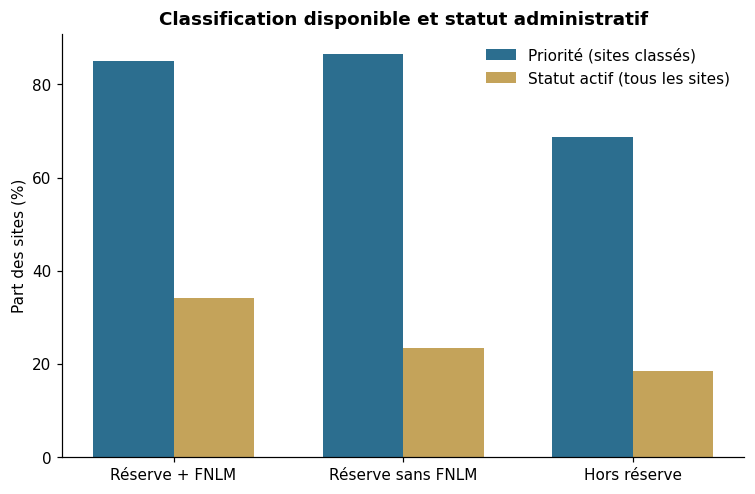

In [23]:
filtres_categories = filtres_groupes(echantillon_final)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.grid": False})

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(3)
largeur = 0.35
ax.bar(x - largeur / 2, stats_categories["priorite_action"] * 100, largeur,
       label="Priorité (sites classés)", color="#2C6E8F")
ax.bar(x + largeur / 2, stats_categories["statut_actif"] * 100, largeur,
       label="Statut actif (tous les sites)", color="#C4A35A")
ax.set_xticks(x, stats_categories["groupe"])
ax.set_ylabel("Part des sites (%)")
ax.set_title("Classification disponible et statut administratif")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)


### Explication du code

La cellule fixe les paramètres communs des figures (résolution, titres en gras) et crée `filtres_categories`, que les sections 2.2, 4.5 et 4.7 réutilisent. Elle trace ensuite, pour la figure 4.1, deux séries de barres par catégorie : la priorité d'action, calculée parmi les seuls sites classés, et le statut actif, calculé sur tous les sites. Les barres sont décalées de part et d'autre de la position centrale (`largeur / 2`) pour être lues côte à côte.

### Interprétation

La figure reprend le tableau 4.1. La priorité d'action y est presque la même dans les deux catégories de réserves et plus faible hors réserve, alors que le statut actif est nettement plus fréquent dans le groupe FNLM. Les deux séries n'ont pas le même dénominateur, ce que la légende rappelle.

## 2.2 Statut administratif des sites  *(rapport 4.1, figure 4.2)*

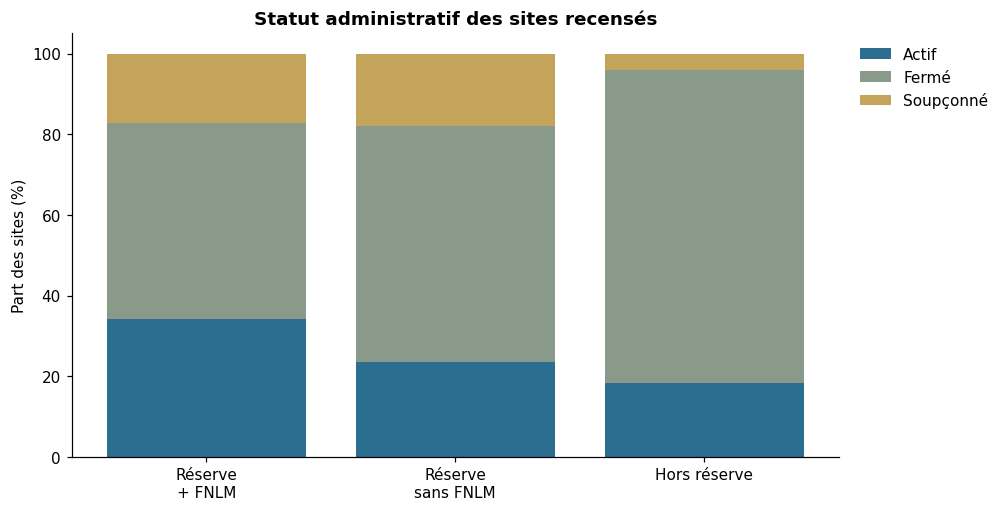

In [24]:
fig, ax = plt.subplots(figsize=(9, 5))
statuts = ["Active", "Closed", "Suspected"]
etiquettes = ["Actif", "Fermé", "Soupçonné"]
bas = np.zeros(3)
for statut, etiquette, couleur in zip(statuts, etiquettes, ["#2C6E8F", "#8A9A8A", "#C4A35A"]):
    valeurs = [echantillon_final.loc[masque, "sitestatus"].eq(statut).mean() * 100 for masque in filtres_categories.values()]
    ax.bar(np.arange(3), valeurs, bottom=bas, label=etiquette, color=couleur)
    bas += np.asarray(valeurs)

ax.set_xticks(
    np.arange(3), [nom.replace(" sans ", "\nsans ").replace(" + ", "\n+ ")
                   for nom in filtres_categories]
)
ax.set_ylabel("Part des sites (%)")
ax.set_title("Statut administratif des sites recensés")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.spines[["top", "right"]].set_visible(False)


### Explication du code

Pour chaque catégorie, la cellule calcule la part de sites actifs, fermés et soupçonnés, puis empile ces parts en barres de 100 %. La légende est placée hors du cadre pour ne pas masquer le haut des barres.

### Interprétation

Les deux catégories de réserves ont une part semblable de sites soupçonnés (17,2 % et 18,0 %), mais le groupe FNLM compte plus de sites actifs (34,2 % contre 23,5 %) et moins de sites fermés (48,6 % contre 58,5 %). Hors réserve, les sites fermés dominent (77,5 %) et les sites soupçonnés sont rares (4,1 %). Le statut actif code les sites soupçonnés à 0, comme les sites fermés. Ce choix pèse surtout sur la comparaison avec les sites hors réserve ; la spécification (f) de la section 4.19 l'examine en retirant les sites soupçonnés.

## 2.3 Répartition provinciale  *(rapport 3.1.3, figure 3.1)*

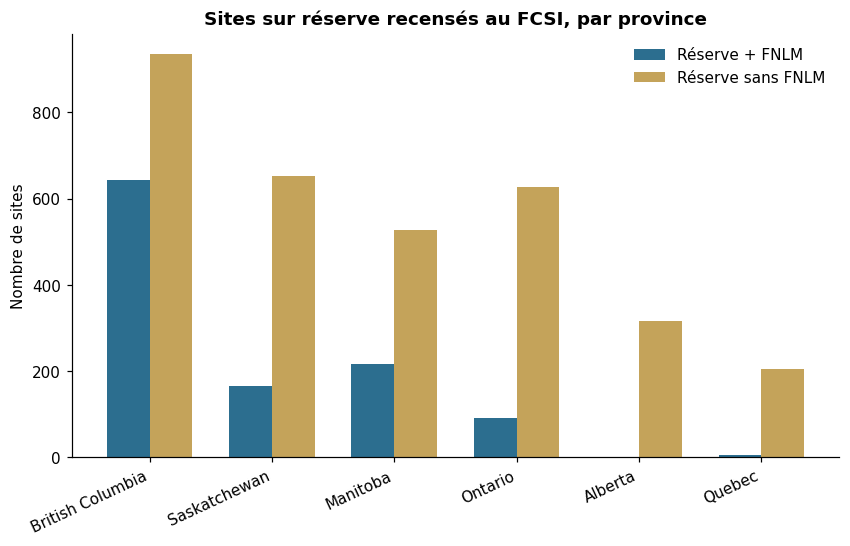

In [25]:
stats_provinces = (
    echantillon_final[echantillon_final["est_reserve"].eq(1)]
    .groupby("province")
    .agg(
        total=("federalsiteidentifier", "size"),
        sites_fnlm=("reserve_lma", "sum"),
        classes_valides=("classification_disponible", "sum"),
        couverture_classe=("classification_disponible", "mean"),
        priorite=("priorite_action", "mean"),
        actif=("statut_actif", "mean"),
    )
    .sort_values("total", ascending=False)
    .reset_index()
)
provinces_principales = stats_provinces.head(6).copy()
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(provinces_principales))
largeur = 0.35
ax.bar(x - largeur / 2, provinces_principales["sites_fnlm"], largeur, label="Réserve + FNLM", color="#2C6E8F")
ax.bar(x + largeur / 2, provinces_principales["total"] - provinces_principales["sites_fnlm"], largeur,
       label="Réserve sans FNLM", color="#C4A35A")
ax.set_xticks(x, provinces_principales["province"], rotation=25, ha="right")
ax.set_ylabel("Nombre de sites")
ax.set_title("Sites sur réserve recensés au FCSI, par province")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)

### Explication du code

La cellule regroupe les sites sur réserve par province et calcule le nombre total de sites, le nombre de sites FNLM, le nombre et la part de sites classés, ainsi que les taux de priorité et de statut actif. Elle trace ensuite, pour les six provinces qui comptent le plus de sites sur réserve, les sites FNLM et non FNLM. `stats_provinces` sert aussi au tableau de la section suivante.

### Interprétation

La Colombie-Britannique concentre 1 578 sites sur réserve, dont 643 sites FNLM, soit 56,8 % de tout le groupe FNLM. Elle devance la Saskatchewan (818 sites, dont 165 FNLM) et le Manitoba (744, dont 216). En Alberta, seuls 2 des 318 sites sont FNLM. Cette répartition inégale justifie les effets fixes provinciaux des modèles et l'analyse séparée de la Colombie-Britannique (section 4.2).

## 2.4 Tableau provincial  *(rapport 3.1.3, tableau 3.1)*

In [26]:
montrer_tableau(
    stats_provinces.assign(non_fnlm=stats_provinces["total"] - stats_provinces["sites_fnlm"]),
    colonnes={
        "province": "Province", "total": "Total", "sites_fnlm": "FNLM", "non_fnlm": "Sans FNLM",
        "classes_valides": "Sites classés", "couverture_classe": "Couverture",
        "priorite": "Priorité", "actif": "Actif",
    },
    formats={colonne: POURCENTAGES for colonne in ["Couverture", "Priorité", "Actif"]},
    titre="Sites sur réserve recensés au FCSI, par province",
)
print(f"Total sur réserve : {int(echantillon_final['est_reserve'].sum()):,} sites")

Province,Total,FNLM,Sans FNLM,Sites classés,Couverture,Priorité,Actif
British Columbia,"1,578",643,935,803,50.9%,85.1%,40.2%
Saskatchewan,818,165,653,153,18.7%,69.3%,12.6%
Manitoba,744,216,528,275,37.0%,89.1%,22.6%
Ontario,718,92,626,424,59.1%,87.7%,17.5%
Alberta,318,2,316,206,64.8%,92.2%,25.2%
Quebec,210,6,204,136,64.8%,91.9%,25.7%
Nova Scotia,42,3,39,1,2.4%,100.0%,7.1%
New Brunswick,38,3,35,6,15.8%,83.3%,10.5%
Northwest Territories,15,0,15,10,66.7%,70.0%,6.7%
Yukon,8,0,8,6,75.0%,100.0%,12.5%


Total sur réserve : 4,503 sites


### Explication du code

La cellule ajoute par soustraction le nombre de sites sans FNLM et affiche le tableau 3.1 pour toutes les provinces et tous les territoires.

### Interprétation

La part de sites classés varie fortement d'une province à l'autre. Elle atteint 50,9 % en Colombie-Britannique, mais seulement 18,7 % en Saskatchewan, où 153 des 818 sites sur réserve ont une classification informative. Le taux de priorité de 69,3 % de la Saskatchewan porte donc sur un petit sous-ensemble de ses sites. À l'Île-du-Prince-Édouard, aucun des cinq sites sur réserve n'est classé, d'où le « — » de la colonne Priorité.

## 2.5 Principales organisations déclarantes  *(rapport 2.4 et 4.8.8)*

In [27]:
table_organisations = (
    echantillon_final.groupby("reportingorganization")
    .agg(
        Tous_les_sites=("federalsiteidentifier", "size"),
        Sites_sur_reserve=("est_reserve", "sum"),
        Sites_FNLM=("reserve_lma", "sum"),
    )
    .sort_values("Tous_les_sites", ascending=False)
    .head(10)
    .reset_index()
    .rename(columns={"reportingorganization": "Organisation déclarante"})
)
montrer_tableau(table_organisations, titre="Principales organisations déclarantes")

Organisation déclarante,Tous_les_sites,Sites_sur_reserve,Sites_FNLM
Fisheries and Oceans Canada,"11,013",2,0
Indigenous Services Canada,"4,418","4,340","1,131"
National Defence,"1,946",4,0
Environment and Climate Change Canada,"1,328",101,0
Crown-Indigenous Relations and Northern Affairs Canada,"1,004",0,0
Royal Canadian Mounted Police,999,0,0
Transport Canada,944,1,0
Agriculture and Agri-Food Canada,544,0,0
Parks Canada Agency,485,0,0
Public Services and Procurement Canada,481,1,0


### Explication du code

La cellule compte, pour chaque organisation fédérale déclarante, le nombre total de sites, de sites sur réserve et de sites FNLM, puis garde les dix organisations qui déclarent le plus de sites.

### Interprétation

Services aux Autochtones Canada (Indigenous Services Canada) déclare 4 340 des 4 503 sites sur réserve (96,4 %) et 1 131 des 1 132 sites FNLM. Tous organismes confondus, elle arrive au deuxième rang (4 418 sites), derrière Pêches et Océans Canada (11 013). Cette concentration rend l'organisation déclarante presque colinéaire au statut de réserve, ce qui explique l'effet du contrôle de l'organisation à la section 4.10.

# Partie 3 — Régressions principales

## 3.1 Outils d'estimation

In [28]:
def ajouter_etoiles(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

NOMS_INDICATEURS = {
    "priorite_action": "Priorité d'action",
    "statut_actif": "Statut actif",
    "haute_priorite_action": "Haute priorité",
}

def choisir_controles(donnees, specification):

    if isinstance(specification, list):
        return specification
    if specification == "aucun":
        return []
    if specification == "province":
        return [c for c in donnees.columns if c.startswith("prov_")]
    if specification == "province_organisation":
        return [c for c in donnees.columns if c.startswith(("prov_", "org_"))]
    raise ValueError(f"Spécification inconnue : {specification}")

def ajuster_mco(d, y, regresseurs, poids=None, type_erreurs="cluster"):
    X = sm.add_constant(d[regresseurs].astype(float), has_constant="add")
    yv = d[y].astype(float)
    ajustement = sm.OLS(yv, X) if poids is None else sm.WLS(yv, X, weights=poids)
    if type_erreurs == "cluster":
        return ajustement.fit(cov_type="cluster",
                              cov_kwds={"groups": d["grappe"], "use_correction": True})
    if type_erreurs == "HC1":
        return ajustement.fit(cov_type="HC1")
    raise ValueError(f"Covariance inconnue : {type_erreurs}")

def lancer_lpm(donnees, y, specification, type_erreurs="cluster", poids_nations=None):
    variables_explicatives = ["reserve_lma", "reserve_non_lma"] + choisir_controles(
        donnees, specification
    )
    d = donnees[[y, "grappe"] + variables_explicatives].copy()
    if poids_nations is not None:
        d["_poids"] = poids_nations.reindex(d.index)
    d = d.dropna()
    poids = None if poids_nations is None else d["_poids"].astype(float)
    return ajuster_mco(d, y, variables_explicatives, poids, type_erreurs)

def tester_ecart_reserves(modele):
    difference = modele.params["reserve_lma"] - modele.params["reserve_non_lma"]
    cov = modele.cov_params()
    variance = (cov.loc["reserve_lma", "reserve_lma"]
                + cov.loc["reserve_non_lma", "reserve_non_lma"]
                - 2 * cov.loc["reserve_lma", "reserve_non_lma"])
    erreur = float(np.sqrt(max(float(variance), 0.0)))
    valeur_p = float(
        modele.wald_test("reserve_lma = reserve_non_lma", use_f=False, scalar=True).pvalue
    )
    return float(difference), erreur, valeur_p

def resume_lpm(modele, indicateur_etudie):

    difference, erreur_difference, p_difference = tester_ecart_reserves(modele)
    resume = {
        "issue": indicateur_etudie,
        "b_fnlm": modele.params["reserve_lma"],
        "se_fnlm": modele.bse["reserve_lma"],
        "p_fnlm": modele.pvalues["reserve_lma"],
        "b_non_fnlm": modele.params["reserve_non_lma"],
        "se_non_fnlm": modele.bse["reserve_non_lma"],
        "p_non_fnlm": modele.pvalues["reserve_non_lma"],
        "difference": difference,
        "se_difference": erreur_difference,
        "p_difference": p_difference,
        "N": int(modele.nobs),
    }
    return resume

NOMS_SPECIFICATIONS = {"aucun": "Sans contrôles", "province": "Effets fixes provinciaux"}

def montrer_resultats_lpm(sorties_regression, indicateur_etudie, titre):

    table = sorties_regression[sorties_regression["issue"].eq(indicateur_etudie)].copy()
    table["Spécification"] = table["specification"].map(NOMS_SPECIFICATIONS)
    for colonne, prefixe in [("Réserve + FNLM", "fnlm"), ("Réserve sans FNLM", "non_fnlm")]:
        b, se, p = f"b_{prefixe}", f"se_{prefixe}_cluster", f"p_{prefixe}_cluster"
        table[colonne] = table.apply(
            lambda r, b=b, se=se, p=p: f'{r[b]:.4f}{ajouter_etoiles(r[p])} ({r[se]:.4f})', axis=1
        )
    table["Écart FNLM − sans FNLM"] = table.apply(
        lambda r: f'{r["difference"]:.4f} ({r["se_difference"]:.4f})', axis=1
    )
    table["N"] = table["N"].astype(int)
    table = table.rename(columns={"p_difference": "p(égalité)", "r2": "R²"})
    montrer_tableau(
        table[[
            "Spécification", "Réserve + FNLM", "Réserve sans FNLM",
            "Écart FNLM − sans FNLM", "p(égalité)", "R²", "N",
        ]],
        titre=titre,
    )

def creer_poids_nations(donnees, y):
    filtre_observe = donnees[y].notna()
    tailles = donnees.loc[filtre_observe].groupby("grappe")[y].transform("size")
    poids_nations = pd.Series(np.nan, index=donnees.index, dtype=float)
    poids_nations.loc[filtre_observe] = 1.0 / tailles.astype(float)
    return poids_nations

def montrer_robustesse(table, titre):
    montrer_tableau(table, titre=titre, colonnes={
        "issue": "Issue", "b_fnlm": "FNLM", "se_fnlm": "ET FNLM",
        "b_non_fnlm": "Sans FNLM", "se_non_fnlm": "ET sans FNLM",
        "difference": "Différence", "p_difference": "p(égalité)", "N": "N",
    })

def lpm_sur_reserve_etendu(donnees, y, supplements=None, poids=False):
    d = donnees[donnees["est_reserve"].eq(1)].copy()
    provinces = pd.get_dummies(d["province"], prefix="prov_res",
                               drop_first=True, dtype=float)
    d = pd.concat([d, provinces], axis=1)
    colonnes = ["reserve_lma"] + list(provinces.columns)

    if supplements == "organisation":
        organisations = pd.get_dummies(d["reportingorganization"], prefix="org_res",
                                       drop_first=True, dtype=float)
        d = pd.concat([d, organisations], axis=1)
        colonnes += list(organisations.columns)
    elif supplements:
        colonnes += list(supplements)

    d = d[[y, "grappe"] + colonnes].dropna()
    poids = 1.0 / d.groupby("grappe")[y].transform("size").astype(float) if poids else None
    return ajuster_mco(d, y, colonnes, poids), d

### Explication du code

Cette cellule définit les outils communs à toutes les estimations, pour que chaque modèle applique la même mécanique.

`ajuster_mco` est l'unique fonction d'ajustement. Elle estime par moindres carrés, pondérés ou non, l'issue sur une constante et les régresseurs, avec des erreurs-types regroupées par grappe (correction de petit échantillon incluse) ou HC1. Elle sert au modèle groupé, au modèle sur réserve et au modèle de cohortes. `choisir_controles` traduit une spécification (« aucun », « province », « province_organisation ») en liste de colonnes. `lancer_lpm` estime l'équation (1), qui régresse l'issue sur `reserve_lma`, `reserve_non_lma` et les contrôles, après retrait des lignes incomplètes. Ses deux coefficients mesurent l'écart de chaque catégorie de réserves par rapport aux sites hors réserve.

`tester_ecart_reserves` calcule l'écart β₁ − β₂, son erreur-type et la valeur p du test de Wald (khi-deux) de β₁ = β₂, qui compare directement les deux catégories de réserves. `resume_lpm` range ces résultats dans un dictionnaire, `montrer_resultats_lpm` les met en forme, `montrer_robustesse` donne la même présentation à tous les tableaux de robustesse, et `ajouter_etoiles` ajoute les étoiles de significativité (`***` à 1 %, `**` à 5 %, `*` à 10 %).

`creer_poids_nations` donne à chaque Première Nation le même poids total, quel que soit son nombre de sites. `lpm_sur_reserve_etendu` estime l'équation (3) sur les seuls sites sur réserve. Les indicatrices provinciales y sont reconstruites sur ce sous-échantillon, et l'on peut y ajouter des contrôles, des effets fixes d'organisation ou des poids. Ces poids égaux par Première Nation sont recalculés sur le sous-échantillon estimé, après le retrait des lignes incomplètes.

## 3.2 Estimation des trois modèles  *(rapport 4.2, tableau 4.2)*

### Modèle 1 : priorité d'action

In [29]:
indicateurs_modeles = list(NOMS_INDICATEURS)
liste_modeles = []
modeles_finaux = {}
for y in indicateurs_modeles:
    for specification in ["aucun", "province"]:
        modele = lancer_lpm(echantillon_final, y, specification, type_erreurs="cluster")
        regression_hc1 = lancer_lpm(echantillon_final, y, specification, type_erreurs="HC1")
        difference, erreur_difference, p_difference = tester_ecart_reserves(modele)
        cle = f"{y}_{specification}"
        modeles_finaux[cle] = modele
        liste_modeles.append(
            {
                "issue": y,
                "specification": specification,
                "b_fnlm": modele.params["reserve_lma"],
                "se_fnlm_cluster": modele.bse["reserve_lma"],
                "p_fnlm_cluster": modele.pvalues["reserve_lma"],
                "se_fnlm_hc1": regression_hc1.bse["reserve_lma"],
                "b_non_fnlm": modele.params["reserve_non_lma"],
                "se_non_fnlm_cluster": modele.bse["reserve_non_lma"],
                "p_non_fnlm_cluster": modele.pvalues["reserve_non_lma"],
                "se_non_fnlm_hc1": regression_hc1.bse["reserve_non_lma"],
                "difference": difference,
                "se_difference": erreur_difference,
                "p_difference": p_difference,
                "r2": modele.rsquared,
                "N": int(modele.nobs),
            }
        )
table_resultats_lpm = pd.DataFrame(liste_modeles)

montrer_resultats_lpm(table_resultats_lpm, "priorite_action", "Modèle 1 — priorité d'action")

Spécification,Réserve + FNLM,Réserve sans FNLM,Écart FNLM − sans FNLM,p(égalité),R²,N
Sans contrôles,0.1628*** (0.0243),0.1789*** (0.0124),-0.0161 (0.0263),0.5408,0.0235,"10,621"
Effets fixes provinciaux,0.1248*** (0.0261),0.1449*** (0.0137),-0.0201 (0.0270),0.4576,0.0394,"10,621"


### Explication du code

La double boucle croise les trois issues avec deux spécifications, sans contrôles puis avec effets fixes provinciaux. Chaque modèle est estimé avec des erreurs-types regroupées par Première Nation, puis avec des erreurs HC1 pour la comparaison de la section 4.1 : les coefficients sont identiques et seules les erreurs-types changent. Les résultats sont empilés dans `table_resultats_lpm`. Les six modèles regroupés sont conservés dans `modeles_finaux`, où la figure 4.3 prend ceux à effets fixes provinciaux. La cellule affiche ensuite le modèle 1.

### Interprétation

Avec effets fixes provinciaux, la probabilité d'être classé prioritaire est supérieure de 12,5 points dans le groupe FNLM et de 14,5 points dans les autres réserves, par rapport aux sites hors réserve classés. Les deux coefficients sont significatifs au seuil de 1 %. Sans contrôles, ils valent 16,3 et 17,9 points : les effets fixes réduisent les deux coefficients sans changer leur comparaison.

L'écart entre les deux catégories de réserves est de −2,0 points et n'est pas significatif (p = 0,458). Les deux groupes de réserves se distinguent des sites hors réserve, mais pas l'un de l'autre. Le R² de 0,039 est faible, ce qui est attendu d'un modèle qui ne contient que deux indicatrices et des effets fixes provinciaux : il mesure des écarts moyens entre catégories, non une prévision site par site.

## 3.3 Modèle 2 : statut actif  *(rapport 4.3.2)*

In [30]:
montrer_resultats_lpm(table_resultats_lpm, "statut_actif", "Modèle 2 — statut actif")

Spécification,Réserve + FNLM,Réserve sans FNLM,Écart FNLM − sans FNLM,p(égalité),R²,N
Sans contrôles,0.1574*** (0.0319),0.0502*** (0.0139),0.1072 (0.0345),0.0019,0.0083,"23,801"
Effets fixes provinciaux,0.1928*** (0.0289),0.0807*** (0.0130),0.1121 (0.0313),0.0003,0.0385,"23,801"


### Explication du code

Les modèles sont déjà estimés à la section 3.2. La cellule extrait les lignes du statut actif et les met en forme.

### Interprétation

Avec effets fixes provinciaux, la probabilité qu'un site soit actif est supérieure de 19,3 points dans le groupe FNLM et de 8,1 points dans les autres réserves, par rapport aux sites hors réserve. L'écart de 11,2 points entre les deux catégories de réserves est significatif (p < 0,001) ; il est de 10,7 points sans contrôles (p = 0,002). Cet écart vient toutefois du modèle groupé. Estimé sur les seuls sites sur réserve, il tombe à 5,3 points (section 3.5).

## 3.4 Modèle 3 : haute priorité  *(rapport 4.3.2 et 4.3.3)*

In [31]:
montrer_resultats_lpm(table_resultats_lpm, "haute_priorite_action", "Modèle 3 — haute priorité")

Spécification,Réserve + FNLM,Réserve sans FNLM,Écart FNLM − sans FNLM,p(égalité),R²,N
Sans contrôles,0.1000*** (0.0319),0.2070*** (0.0190),-0.1070 (0.0368),0.0036,0.0403,"10,621"
Effets fixes provinciaux,0.0042 (0.0320),0.1529*** (0.0209),-0.1487 (0.0367),0.0001,0.0840,"10,621"


### Explication du code

Comme pour les deux modèles précédents, la cellule met en forme les lignes de la haute priorité. Cette issue vaut 1 seulement pour « High Priority for Action » et reste manquante lorsque la classification n'est pas informative. Elle sert à examiner la troisième proposition du rapport (P3).

### Interprétation

Avec effets fixes provinciaux, le coefficient du groupe FNLM est de 0,4 point et ne se distingue pas de zéro, alors que celui des autres réserves atteint 15,3 points. L'écart de −14,9 points entre les deux catégories de réserves est significatif (p < 0,001). Sans contrôles, le coefficient FNLM vaut 10,0 points et il est significatif au seuil de 1 %. Les effets fixes provinciaux le ramènent près de zéro : pour cette issue, la répartition provinciale du groupe FNLM pèse lourd.

Les résultats changent donc d'une issue à l'autre. Par rapport aux autres réserves, le groupe FNLM ne se distingue pas pour la priorité d'action, compte davantage de dossiers actifs et moins de dossiers de haute priorité. Dans les six modèles, le R² va de 0,008 à 0,084. Ces coefficients mesurent des écarts conditionnels de probabilité, et non un effet causal du régime FNLM.

## 3.5 Équation (3) : sites sur réserve seulement  *(rapport 4.3.4, tableau 4.4 ; figure 4.3)*

Issue,δ (sur réserve),ET,Valeur p,β₁ − β₂ (modèle groupé),Écart entre les deux,N,Grappes
Priorité d'action,0.0053,0.0260,0.8374,-0.0201,+0.0254,"2,027",553
Statut actif,0.0526,0.0275,0.0561,0.1121,-0.0596,"4,503",692
Haute priorité,-0.1006,0.0377,0.0076,-0.1487,+0.0481,"2,027",553


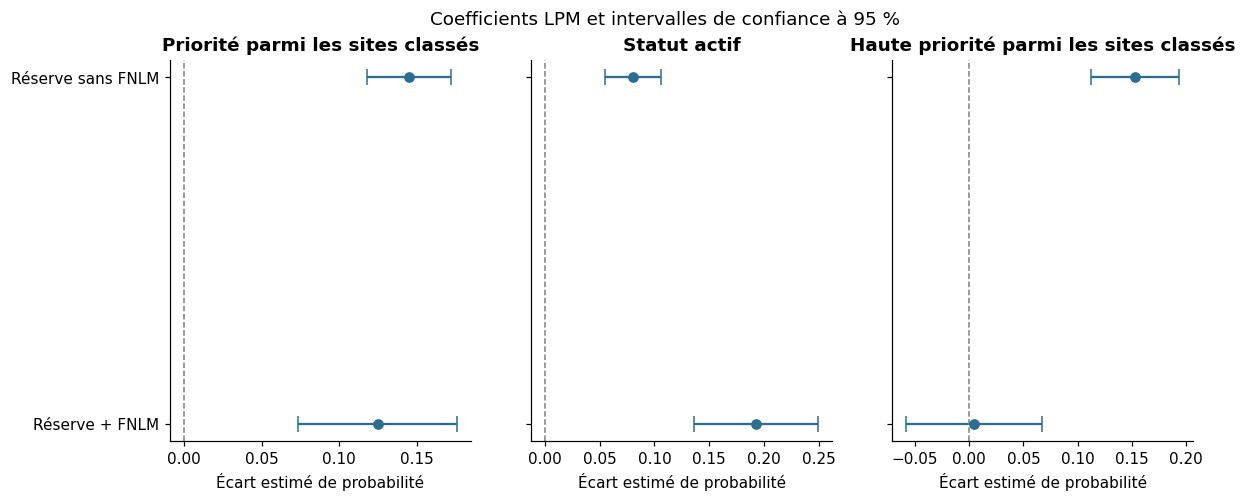

In [32]:
lignes_sur_reserve = []
for y in indicateurs_modeles:
    modele_res, donnees_res = lpm_sur_reserve_etendu(echantillon_final, y)
    ligne = table_resultats_lpm[
        table_resultats_lpm["issue"].eq(y) & table_resultats_lpm["specification"].eq("province")
    ].iloc[0]
    lignes_sur_reserve.append({
        "issue": NOMS_INDICATEURS[y],
        "delta": modele_res.params["reserve_lma"],
        "erreur_type": modele_res.bse["reserve_lma"],
        "valeur_p": modele_res.pvalues["reserve_lma"],
        "ecart_groupe": ligne["difference"],
        "difference": modele_res.params["reserve_lma"] - ligne["difference"],
        "N": int(modele_res.nobs),
        "grappes": donnees_res["grappe"].nunique(),
    })

table_sur_reserve = pd.DataFrame(lignes_sur_reserve)

montrer_tableau(
    table_sur_reserve,
    colonnes={
        "issue": "Issue", "delta": "δ (sur réserve)", "erreur_type": "ET",
        "valeur_p": "Valeur p", "ecart_groupe": "β₁ − β₂ (modèle groupé)",
        "difference": "Écart entre les deux", "N": "N", "grappes": "Grappes",
    },
    formats={"Écart entre les deux": "{:+.4f}"},
    titre="Écart FNLM estimé sur les seuls sites sur réserve",
)


fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), sharey=True)
for ax, (cle, titre) in zip(
    axes,
    [
        ("priorite_action_province", "Priorité parmi les sites classés"),
        ("statut_actif_province", "Statut actif"),
        ("haute_priorite_action_province", "Haute priorité parmi les sites classés"),
    ],
):
    regression_graphique = modeles_finaux[cle]
    variables_explicatives = ["reserve_lma", "reserve_non_lma"]
    coefs = [regression_graphique.params[v] for v in variables_explicatives]
    erreurs = [1.96 * regression_graphique.bse[v] for v in variables_explicatives]
    positions = np.arange(2)
    ax.errorbar(coefs, positions, xerr=erreurs, fmt="o", color="#2C6E8F", capsize=5)
    ax.axvline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_yticks(positions, ["Réserve + FNLM", "Réserve sans FNLM"])
    ax.set_xlabel("Écart estimé de probabilité")
    ax.set_title(titre)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Coefficients LPM et intervalles de confiance à 95 %");


### Explication du code

**Problème :** les modèles précédents gardent les sites hors réserve comme catégorie de référence. L'écart entre les deux catégories de réserves n'y est obtenu qu'indirectement, par β₁ − β₂, et les effets fixes provinciaux sont estimés pour l'essentiel sur des sites hors réserve (19 298 des 23 801).

**Solution :** `lpm_sur_reserve_etendu` estime y = α + δ·FNLM + effets fixes provinciaux + ε sur les seuls sites sur réserve, de sorte que δ mesure directement l'écart entre les réserves FNLM et les autres. `reserve_non_lma` n'y figure pas, car il est le complément exact de `reserve_lma` dans ce sous-échantillon. La cellule compare δ à β₁ − β₂ du modèle groupé avec effets fixes provinciaux. Elle trace ensuite la figure 4.3, qui présente les coefficients du modèle groupé, et non δ, avec leur intervalle de confiance à 95 % (± 1,96 erreur-type regroupée).

### Interprétation

Les modèles de priorité portent sur les 2 027 sites sur réserve classés (553 grappes), celui du statut actif sur les 4 503 sites sur réserve (692 grappes). Estimé sur ces seuls sites, l'écart vaut +0,5 point pour la priorité d'action (p = 0,837), +5,3 points pour le statut actif (p = 0,056) et −10,1 points pour la haute priorité (p = 0,008). Seul l'écart de haute priorité est significatif au seuil de 5 %.

Ces écarts s'éloignent de ceux du modèle groupé de +2,5, −6,0 et +4,8 points. L'écart de statut actif passe ainsi de 11,2 à 5,3 points, et celui de haute priorité de −14,9 à −10,1 points. Le rapport s'appuie sur cette estimation directe pour examiner les propositions P2 et P3. Sur la figure, seul l'intervalle du coefficient FNLM pour la haute priorité croise zéro.

# Partie 4 — Analyses de robustesse

## 4.1 Sensibilité au choix des erreurs-types  *(rapport 4.8.2, tableau 4.9)*

In [33]:
table_ecarts_types = table_resultats_lpm.assign(
    Issue=table_resultats_lpm["issue"].map(NOMS_INDICATEURS),
    Spécification=table_resultats_lpm["specification"].map(NOMS_SPECIFICATIONS),
    Ratio=table_resultats_lpm["se_fnlm_cluster"] / table_resultats_lpm["se_fnlm_hc1"],
)
montrer_tableau(
    table_ecarts_types,
    colonnes={
        "Issue": "Issue", "Spécification": "Spécification",
        "b_fnlm": "Coefficient FNLM", "se_fnlm_cluster": "ET regroupée", "se_fnlm_hc1": "ET HC1",
        "Ratio": "Ratio", "b_non_fnlm": "Coefficient sans FNLM",
        "se_non_fnlm_cluster": "ET regroupée (sans FNLM)", "se_non_fnlm_hc1": "ET HC1 (sans FNLM)",
    },
    formats={"Ratio": "{:.2f}"},
    titre="Erreurs-types regroupées et HC1 — coefficients identiques",
)

Issue,Spécification,Coefficient FNLM,ET regroupée,ET HC1,Ratio,Coefficient sans FNLM,ET regroupée (sans FNLM),ET HC1 (sans FNLM)
Priorité d'action,Sans contrôles,0.1628,0.0243,0.0171,1.42,0.1789,0.0124,0.0100
Priorité d'action,Effets fixes provinciaux,0.1248,0.0261,0.0188,1.39,0.1449,0.0137,0.0113
Statut actif,Sans contrôles,0.1574,0.0319,0.0144,2.22,0.0502,0.0139,0.0078
Statut actif,Effets fixes provinciaux,0.1928,0.0289,0.0145,1.99,0.0807,0.0130,0.0082
Haute priorité,Sans contrôles,0.1000,0.0319,0.0196,1.63,0.2070,0.0190,0.0125
Haute priorité,Effets fixes provinciaux,0.0042,0.0320,0.0211,1.51,0.1529,0.0209,0.0134


### Explication du code

La cellule reprend `table_resultats_lpm` et place côte à côte, pour chaque modèle, l'erreur-type regroupée et l'erreur-type HC1 des deux coefficients de réserve. La colonne Ratio divise la première par la seconde pour le coefficient FNLM. Un ratio supérieur à 1 signale que les résidus des sites d'une même Première Nation sont corrélés positivement.

### Interprétation

Seules les erreurs-types changent d'une méthode à l'autre. Avec effets fixes provinciaux, le ratio vaut 1,39 pour la priorité d'action, 1,99 pour le statut actif et 1,51 pour la haute priorité. Pour le statut actif, ignorer le regroupement diviserait l'erreur-type par deux (0,015 au lieu de 0,029) et doublerait la statistique de test.

Les sites d'une même nation partagent une gouvernance, un déclarant et souvent un historique. Les traiter comme indépendants surestimerait l'information disponible ; le regroupement est donc retenu pour toute l'interprétation.

## 4.2 Sous-échantillon de la Colombie-Britannique  *(rapport 4.4, tableau 4.5)*

In [34]:
echantillon_cb = echantillon_final[echantillon_final["province"].eq("British Columbia")].copy()
table_resultats_cb = pd.DataFrame([
    resume_lpm(lancer_lpm(echantillon_cb, y, "aucun"), y)
    for y in indicateurs_modeles
])
montrer_robustesse(table_resultats_cb, "Robustesse — sous-échantillon de la Colombie-Britannique")

Issue,FNLM,ET FNLM,Sans FNLM,ET sans FNLM,Différence,p(égalité),N
priorite_action,0.1062,0.0266,0.0873,0.0249,0.0189,0.5425,"1,824"
statut_actif,0.3467,0.0358,0.2294,0.0237,0.1172,0.0054,"4,781"
haute_priorite_action,-0.0403,0.0447,0.0530,0.0380,-0.0933,0.0897,"1,824"


### Explication du code

La cellule réestime l'équation (1) sur les seuls sites de la Colombie-Britannique, sans contrôles : la province y est constante, et des effets fixes provinciaux n'auraient rien à absorber. β₁ − β₂ y devient l'écart brut entre les sites FNLM et les autres sites sur réserve de la province.

### Interprétation

Le sous-échantillon compte 4 781 sites, dont 1 578 sur réserve et 643 FNLM ; les modèles de priorité portent sur ses 1 824 sites classés. L'écart de haute priorité entre les deux catégories de réserves est de −9,3 points (p = 0,090), presque identique au δ national de −10,1 points (section 3.5), mais moins précis. L'écart de statut actif atteint 11,7 points (p = 0,005), contre 5,3 points pour l'ensemble des réserves. Pour la priorité d'action, l'écart de +1,9 point n'est pas significatif (p = 0,543). La province qui fournit 56,8 % des sites FNLM reproduit donc le signe des deux écarts nationaux, avec un écart de statut actif plus grand.

## 4.3 Dépenses de remédiation et d'évaluation  *(rapport 4.5 et 4.5.1, tableau 4.6)*

In [35]:
DEPENSES_ANALYSEES = ["totalremediationexpenditure", "totalassessmentexpenditure"]

depenses_par_annee = panel_fcsi_complet.copy()
depenses_par_annee[COLONNES_DEPENSES] = (
    depenses_par_annee[COLONNES_DEPENSES].apply(pd.to_numeric, errors="coerce").astype(float)
)

def agreger_depenses(panel, colonnes):
    par_site = panel.groupby("federalsiteidentifier")
    depenses_par_site = (
        par_site[colonnes].sum(min_count=1)
        .join(par_site["fiscalyear"].nunique().rename("exercices_observes"))
        .reset_index()
    )
    return echantillon_final[
        ["federalsiteidentifier", "reserve_lma", "reserve_non_lma", "est_reserve"]
    ].merge(depenses_par_site, on="federalsiteidentifier", how="left")

base_depenses = agreger_depenses(depenses_par_annee, COLONNES_DEPENSES)

liste_depenses = []
for libelle, masque in filtres_groupes(base_depenses).items():
    exercices = base_depenses.loc[masque, "exercices_observes"]
    for variable in DEPENSES_ANALYSEES:
        x = base_depenses.loc[masque, variable]
        x_observe = x.dropna()
        liste_depenses.append({
            "groupe": libelle,
            "variable": variable,
            "moyenne_cumulative_nominale": x.mean(),
            "moyenne_par_exercice_observe": (x / exercices).mean(),
            "mediane_cumulative": x.median(),
            "part_positive": x_observe.gt(0).mean(),
            "mediane_si_positive": x_observe[x_observe > 0].median(),
            "N_non_manquant": int(x.notna().sum()),
            "exercices_moyens": exercices.mean(),
        })
table_depenses = pd.DataFrame(liste_depenses)


montrer_tableau(
    table_depenses.replace({"totalremediationexpenditure": "Remédiation",
                            "totalassessmentexpenditure": "Évaluation"}),
    colonnes={
        "groupe": "Catégorie", "variable": "Dépense",
        "moyenne_cumulative_nominale": "Somme moyenne observée",
        "moyenne_par_exercice_observe": "Moyenne par exercice",
        "mediane_cumulative": "Médiane observée", "part_positive": "Part positive",
        "mediane_si_positive": "Médiane si positive", "N_non_manquant": "N",
        "exercices_moyens": "Exercices moyens",
    },
    formats={
        "Somme moyenne observée": "${:,.0f}", "Moyenne par exercice": "${:,.0f}",
        "Médiane observée": "${:,.0f}", "Part positive": "{:.1%}",
        "Médiane si positive": "${:,.0f}", "Exercices moyens": "{:.1f}",
    },
    titre="Dépenses annuelles observées, agrégées par site",
)

Catégorie,Dépense,Somme moyenne observée,Moyenne par exercice,Médiane observée,Part positive,Médiane si positive,N,Exercices moyens
Réserve + FNLM,Remédiation,"$75,513","$8,843",$0,11.5%,"$101,324","1,132",8.6
Réserve + FNLM,Évaluation,"$12,758","$1,644",$0,41.3%,"$12,853","1,132",8.6
Réserve sans FNLM,Remédiation,"$144,287","$14,308",$0,20.4%,"$69,236","3,371",9.4
Réserve sans FNLM,Évaluation,"$16,476","$1,956",$0,49.8%,"$6,189","3,371",9.4
Hors réserve,Remédiation,"$282,237","$19,689",$0,17.2%,"$43,747","19,243",8.0
Hors réserve,Évaluation,"$21,083","$2,561","$1,106",52.4%,"$10,000","19,243",8.0


### Explication du code

Les montants sont d'abord convertis en nombres. `agreger_depenses` additionne ensuite les dépenses de chaque site sur tous les exercices observés, compte ces exercices et rattache le résultat aux catégories de l'échantillon analytique ; la même fonction sert aux dollars constants (section 4.4). Pour la remédiation et l'évaluation, la cellule calcule la somme moyenne par site, la moyenne par exercice observé, la médiane, la part de sites avec une dépense positive et la médiane parmi ces sites. Une moyenne seule décrirait mal une distribution qui combine beaucoup de zéros et quelques projets très coûteux.

### Interprétation

La médiane de la dépense de remédiation est nulle dans les trois groupes : la plupart des sites n'en déclarent aucune. La dépense moyenne atteint 75 513 \$ par site FNLM, contre 144 287 \$ dans les autres réserves et 282 237 \$ hors réserve. Par exercice observé, ces montants deviennent 8 843 \$, 14 308 \$ et 19 689 \$. Seuls 11,5 % des sites FNLM ont une dépense de remédiation positive, contre 20,4 % et 17,2 %.

Parmi les sites qui dépensent, l'ordre s'inverse, avec une médiane de 101 324 \$ pour le groupe FNLM, contre 69 236 \$ et 43 747 \$. Moins de sites FNLM engagent des dépenses, mais ceux qui le font engagent des montants plus élevés. L'évaluation suit le même ordre pour la moyenne (12 758 \$, 16 476 \$ et 21 083 \$), mais elle est bien plus répandue, avec 41,3 %, 49,8 % et 52,4 % de sites qui en déclarent.

Ces chiffres ne mesurent pas un sous-financement, car ils ne tiennent compte ni de la taille des sites, ni de leur avancement, ni des responsabilités financières. Hors réserve, 19 243 sites sont comptés au lieu de 19 298 : les 55 sites sans exercice lisible sont absents du panel de dépenses.

## 4.4 Dépenses en dollars constants  *(rapport 4.5)*

In [36]:
IPC_CANADA = {
    1993: 85.6, 1994: 85.7, 1995: 87.6, 1996: 88.9, 1997: 90.4, 1998: 91.3,
    1999: 92.9, 2000: 95.4, 2001: 97.8, 2002: 100.0, 2003: 102.8, 2004: 104.7,
    2005: 107.0, 2006: 109.1, 2007: 111.5, 2008: 114.1, 2009: 114.4, 2010: 116.5,
    2011: 119.9, 2012: 121.7, 2013: 122.8, 2014: 125.2, 2015: 126.6, 2016: 128.4,
    2017: 130.4, 2018: 133.4, 2019: 136.0, 2020: 137.0, 2021: 141.6, 2022: 151.2,
    2023: 157.1,
}
ANNEE_BASE_DOLLARS = 2022

panel_reel = depenses_par_annee.copy()
panel_reel["ipc"] = panel_reel["annee_debut"].map(IPC_CANADA)
if panel_reel["ipc"].isna().any():
    exercices = sorted(panel_reel.loc[panel_reel["ipc"].isna(), "annee_debut"].unique())
    raise ValueError(f"Exercices sans indice des prix : {exercices}")

facteur_reel = IPC_CANADA[ANNEE_BASE_DOLLARS] / panel_reel["ipc"]
COLONNES_DEPENSES_REELLES = [c + "_reel" for c in COLONNES_DEPENSES]
for nominale, reelle in zip(COLONNES_DEPENSES, COLONNES_DEPENSES_REELLES):
    panel_reel[reelle] = panel_reel[nominale] * facteur_reel

base_depenses_reel = agreger_depenses(panel_reel, COLONNES_DEPENSES + COLONNES_DEPENSES_REELLES)

lignes_reelles = []
for libelle, masque in filtres_groupes(base_depenses_reel).items():
    exercices = base_depenses_reel.loc[masque, "exercices_observes"]
    for variable in DEPENSES_ANALYSEES:
        for suffixe, unite in [("", "courants"), ("_reel", f"constants {ANNEE_BASE_DOLLARS}")]:
            x = base_depenses_reel.loc[masque, variable + suffixe]
            lignes_reelles.append({
                "Catégorie": libelle,
                "Dépense": "Remédiation" if "remediation" in variable else "Évaluation",
                "Dollars": unite,
                "Somme moyenne": x.mean(),
                "Moyenne par exercice": (x / exercices).mean(),
                "Médiane si positive": x[x > 0].median(),
            })
table_depenses_reelles = pd.DataFrame(lignes_reelles)
montrer_tableau(
    table_depenses_reelles,
    formats={"Somme moyenne": "${:,.0f}", "Moyenne par exercice": "${:,.0f}",
             "Médiane si positive": "${:,.0f}"},
    titre=f"Dépenses en dollars courants et en dollars constants de {ANNEE_BASE_DOLLARS}",
)

panel_categories = panel_reel.merge(
    echantillon_final[["federalsiteidentifier", "reserve_lma", "reserve_non_lma", "est_reserve"]],
    on="federalsiteidentifier", how="inner",
)
print()
for libelle, masque in filtres_groupes(panel_categories).items():
    d = panel_categories[masque]
    poids = d["totalremediationexpenditure"].fillna(0).clip(lower=0)
    if float(poids.sum()) <= 0:
        print(f"{libelle:20s} aucune depense de remediation positive : "
              "annee moyenne des depenses indefinie")
        continue
    annee = np.average(d["annee_debut"], weights=poids)
    print(f"{libelle:20s} annee moyenne des depenses de remediation : {annee:.1f}")

remed = table_depenses_reelles[table_depenses_reelles["Dépense"].eq("Remédiation")]
resume = remed.pivot(index="Catégorie", columns="Dollars", values="Somme moyenne")
COLONNE_REELLE = f"constants {ANNEE_BASE_DOLLARS}"
assert (list(resume["courants"].sort_values(ascending=False).index)
        == list(resume[COLONNE_REELLE].sort_values(ascending=False).index)), (
    "La déflation change l'ordre des catégories : corriger la section 4.5 du rapport.")

comparaison = resume.copy()
comparaison["Facteur implicite"] = comparaison[COLONNE_REELLE] / comparaison["courants"]
reference = "Réserve + FNLM"
comparaison["Rapport aux sites FNLM, courants"] = (
    comparaison["courants"] / comparaison.loc[reference, "courants"])
comparaison[f"Rapport aux sites FNLM, {COLONNE_REELLE}"] = (
    comparaison[COLONNE_REELLE] / comparaison.loc[reference, COLONNE_REELLE])

montrer_tableau(
    comparaison.reset_index(),
    formats={"courants": "${:,.0f}", COLONNE_REELLE: "${:,.0f}",
             "Facteur implicite": "{:.2f}",
             "Rapport aux sites FNLM, courants": "{:.2f}",
             f"Rapport aux sites FNLM, {COLONNE_REELLE}": "{:.2f}"},
    titre="Facteurs de deflation et rapports entre categories, depenses de remediation",
)


Catégorie,Dépense,Dollars,Somme moyenne,Moyenne par exercice,Médiane si positive
Réserve + FNLM,Remédiation,courants,"$75,513","$8,843","$101,324"
Réserve + FNLM,Remédiation,constants 2022,"$90,013","$10,775","$118,806"
Réserve + FNLM,Évaluation,courants,"$12,758","$1,644","$12,853"
Réserve + FNLM,Évaluation,constants 2022,"$15,742","$1,986","$15,603"
Réserve sans FNLM,Remédiation,courants,"$144,287","$14,308","$69,236"
Réserve sans FNLM,Remédiation,constants 2022,"$176,806","$18,016","$87,950"
Réserve sans FNLM,Évaluation,courants,"$16,476","$1,956","$6,189"
Réserve sans FNLM,Évaluation,constants 2022,"$20,607","$2,402","$8,322"
Hors réserve,Remédiation,courants,"$282,237","$19,689","$43,747"
Hors réserve,Remédiation,constants 2022,"$335,514","$23,455","$52,822"



Réserve + FNLM       annee moyenne des depenses de remediation : 2015.2
Réserve sans FNLM    annee moyenne des depenses de remediation : 2013.5
Hors réserve         annee moyenne des depenses de remediation : 2015.3


Dollars,Catégorie,constants 2022,courants,Facteur implicite,"Rapport aux sites FNLM, courants","Rapport aux sites FNLM, constants 2022"
,Hors réserve,"$335,514","$282,237",1.19,3.74,3.73
,Réserve + FNLM,"$90,013","$75,513",1.19,1.00,1.00
,Réserve sans FNLM,"$176,806","$144,287",1.23,1.91,1.96


### Explication du code

La cellule repart du panel de dépenses déjà converti en nombres à la section 4.3 (`depenses_par_annee`), pour que les deux sections utilisent les mêmes définitions. Elle convertit chaque dépense en dollars de 2022 avec l'indice des prix à la consommation d'ensemble du Canada, en moyenne annuelle et en base 2002 = 100 (Statistique Canada, tableau 18-10-0005-01). Chaque exercice reçoit l'indice de son année de début, où tombent neuf de ses douze mois (d'avril à décembre), et le code s'arrête si un exercice n'a pas d'indice. Les montants sont ensuite agrégés avec la même fonction `agreger_depenses` qu'à la section 4.3.

La cellule calcule aussi l'année moyenne des dépenses de remédiation de chaque catégorie, pondérée par les montants, car la déflation peut modifier la comparaison de deux catégories qui dépensent à des moments différents. Les poids sont les dépenses de remédiation positives. Une catégorie qui n'en a aucune n'a donc pas d'année moyenne définie, et la cellule l'indique au lieu de diviser par zéro. Une assertion vérifie que l'ordre des trois catégories ne change pas en dollars constants, comme l'indique la section 4.5 du rapport.

### Interprétation

En dollars de 2022, la dépense moyenne de remédiation passe à 90 013 \$ pour le groupe FNLM, 176 806 \$ pour les autres réserves et 335 514 \$ hors réserve, et l'ordre reste le même. Les dépenses des autres réserves sont un peu plus anciennes (année moyenne 2013,5, contre 2015,2 et 2015,3), d'où un facteur de déflation légèrement plus élevé (1,23 contre 1,19). Le rapport aux sites FNLM passe ainsi de 1,91 à 1,96 pour les autres réserves, et de 3,74 à 3,73 hors réserve.

## 4.5 Nature des contaminants  *(rapport 4.6, tableau 4.7)*

In [37]:
MOTIFS_CONTAMINANTS = {
    "hydrocarbures_petrolier": r"petroleum|\bPHCs?\b",
    "metaux_metalloides": r"metal|metalloid|organometallic",
    "HAP": r"\bPAHs?\b|polycyclic aromatic",
}

liste_contaminants = echantillon_final["mediumcontaminants"].fillna("").astype(str)
filtre_contaminants_connus = liste_contaminants.str.strip().ne("")
familles_contaminants = {nom: liste_contaminants.str.contains(motif, case=False)
                         for nom, motif in MOTIFS_CONTAMINANTS.items()}

liste_contaminants_groupes = []
for libelle, masque in filtres_categories.items():
    denominateur = masque & filtre_contaminants_connus
    n_total, n_information = int(masque.sum()), int(denominateur.sum())
    liste_contaminants_groupes.append({
        "groupe": libelle,
        "N_total": n_total,
        "N_information": n_information,
        "couverture": n_information / n_total,
        **{nom: float(indicateur[denominateur].mean())
           for nom, indicateur in familles_contaminants.items()},
    })
table_contaminants = pd.DataFrame(liste_contaminants_groupes)
montrer_tableau(
    table_contaminants,
    colonnes={
        "groupe": "Catégorie", "N_total": "N total", "N_information": "N renseigné",
        "couverture": "Couverture", "hydrocarbures_petrolier": "Hydrocarbures pétroliers",
        "metaux_metalloides": "Métaux et métalloïdes", "HAP": "HAP",
    },
    formats={colonne: POURCENTAGES for colonne in [
        "Couverture", "Hydrocarbures pétroliers", "Métaux et métalloïdes", "HAP",
    ]},
    titre="Catégories non exclusives de contaminants",
)

Catégorie,N total,N renseigné,Couverture,Hydrocarbures pétroliers,Métaux et métalloïdes,HAP
Réserve + FNLM,"1,132",798,70.5%,60.3%,41.5%,48.1%
Réserve sans FNLM,"3,371","2,208",65.5%,73.1%,27.8%,48.0%
Hors réserve,"19,298","9,473",49.1%,44.5%,67.3%,36.1%


### Explication du code

Trois familles de contaminants sont repérées par expression régulière dans le champ texte `mediumcontaminants` : hydrocarbures pétroliers, métaux et métalloïdes, hydrocarbures aromatiques polycycliques (HAP). Les familles ne sont pas exclusives, car un site peut en contenir plusieurs. Le dénominateur ne retient que les sites dont le champ est renseigné, pour ne pas confondre absence de contaminant et absence d'information.

### Interprétation

Parmi les sites renseignés, les hydrocarbures pétroliers touchent 60,3 % des sites FNLM, 73,1 % des autres sites sur réserve et 44,5 % des sites hors réserve. Les métaux et métalloïdes suivent un autre ordre (41,5 %, 27,8 % et 67,3 %). Les HAP ont une fréquence presque identique dans les deux groupes sur réserve (48,1 % et 48,0 %), contre 36,1 % hors réserve. La couverture du champ va de 70,5 % dans le groupe FNLM à 49,1 % hors réserve ; ces proportions ne portent que sur les sites renseignés.

## 4.6 Étape la plus élevée enregistrée  *(rapport 4.7)*

In [38]:
montrer_tableau(
    stats_categories,
    colonnes={"groupe": "Catégorie", "N_etape_valide": "N valide",
              "etape_moyenne": "Étape moyenne", "etape_9_plus": "Étape 9 ou plus"},
    formats={"Étape moyenne": "{:.2f}", "Étape 9 ou plus": POURCENTAGES},
    titre="Étape la plus élevée enregistrée",
)

Catégorie,N valide,Étape moyenne,Étape 9 ou plus
Réserve + FNLM,"1,132",4.32,18.7%
Réserve sans FNLM,"3,371",4.52,23.9%
Hors réserve,"19,243",3.86,11.1%


### Explication du code

La cellule affiche les statistiques d'étape déjà calculées dans `stats_categories` : le nombre de sites renseignés, l'étape moyenne et la part de sites ayant atteint l'étape 9 ou plus, sur une échelle de 1 à 10.

### Interprétation

L'étape moyenne vaut 4,32 dans le groupe FNLM, 4,52 dans les autres réserves et 3,86 hors réserve, et la part de sites à l'étape 9 ou plus est de 18,7 %, 23,9 % et 11,1 %. Les dossiers FNLM sont en moyenne un peu moins avancés que ceux des autres réserves, alors qu'ils sont plus souvent actifs, ce qui concorde avec leur part plus faible de sites fermés (section 2.2). Les 55 valeurs manquantes sont toutes hors réserve (19 243 sites renseignés sur 19 298).

## 4.7 Population autour des sites  *(rapport 3.7 et 4.8.7)*

In [39]:
if "populationatradius1km" not in echantillon_final.columns:
    raise KeyError("Le champ populationatradius1km est absent du fichier FCSI.")
liste_population = []
for libelle, masque in filtres_categories.items():
    valeurs = pd.to_numeric(echantillon_final.loc[masque, "populationatradius1km"], errors="coerce")
    liste_population.append({
        "Catégorie": libelle,
        "Population médiane": valeurs.median(),
        "N renseigné": int(valeurs.notna().sum()),
        "Couverture": valeurs.notna().mean(),
    })
montrer_tableau(
    pd.DataFrame(liste_population),
    formats={"Population médiane": "{:,.0f}", "Couverture": POURCENTAGES},
    titre="Population dans un rayon d'un kilomètre",
)

Catégorie,Population médiane,N renseigné,Couverture
Réserve + FNLM,114,"1,079",95.3%
Réserve sans FNLM,47,"3,010",89.3%
Hors réserve,100,"13,472",69.8%


### Explication du code

La cellule vérifie d'abord que le champ de population à un kilomètre existe, puis calcule pour chaque catégorie la population médiane, le nombre de sites renseignés et la couverture du champ. La médiane est préférée à la moyenne, très sensible aux quelques sites situés en zone urbaine dense.

### Interprétation

La population médiane à un kilomètre est de 114 personnes autour des sites FNLM, de 47 autour des autres sites sur réserve et de 100 hors réserve. La couverture du champ diffère beaucoup : 95,3 % pour les sites FNLM, 89,3 % pour les autres réserves et 69,8 % hors réserve. Ajouter ce contrôle à un modèle réduit donc surtout l'échantillon hors réserve, ce dont la section 4.11 tient compte.

## 4.8 Modèles non linéaires : probit et logit  *(rapport 4.8.1, tableau 4.8)*

In [40]:
variables_probit_logit = ["reserve_lma", "reserve_non_lma"] + effets_fixes_province
liste_modeles_non_lineaires = []
for y in indicateurs_modeles:
    d = echantillon_final[[y, "grappe"] + variables_probit_logit].dropna().copy()
    X = sm.add_constant(d[variables_probit_logit].astype(float), has_constant="add")
    for classe_modele, nom_modele in [(sm.Probit, "probit"), (sm.Logit, "logit")]:
        modele = classe_modele(d[y].astype(float), X).fit(
            disp=0,
            maxiter=300,
            cov_type="cluster",
            cov_kwds={"groups": d["grappe"], "use_correction": True},
        )
        effets = modele.get_margeff(
            at="overall", method="dydx", dummy=True
        ).summary_frame()
        p_egalite = tester_ecart_reserves(modele)[2]
        liste_modeles_non_lineaires.append(
            {
                "issue": y,
                "modele": nom_modele,
                "emm_fnlm": effets.loc["reserve_lma", "dy/dx"],
                "se_fnlm": effets.loc["reserve_lma", "Std. Err."],
                "p_fnlm": effets.loc["reserve_lma", "Pr(>|z|)"],
                "emm_non_fnlm": effets.loc["reserve_non_lma", "dy/dx"],
                "se_non_fnlm": effets.loc["reserve_non_lma", "Std. Err."],
                "p_non_fnlm": effets.loc["reserve_non_lma", "Pr(>|z|)"],
                "p_egalite_coefficients_latents": p_egalite,
                "pseudo_r2": modele.prsquared,
                "N": int(modele.nobs),
            }
        )
table_modeles_non_lineaires = pd.DataFrame(liste_modeles_non_lineaires)


montrer_tableau(
    table_modeles_non_lineaires,
    colonnes={
        "issue": "Issue", "modele": "Modèle", "emm_fnlm": "EMM FNLM",
        "se_fnlm": "ET FNLM", "emm_non_fnlm": "EMM sans FNLM",
        "se_non_fnlm": "ET sans FNLM", "p_egalite_coefficients_latents": "p(égalité)",
        "pseudo_r2": "Pseudo-R²", "N": "N",
    },
    titre="Effets marginaux moyens — probit et logit",
)

Issue,Modèle,EMM FNLM,ET FNLM,EMM sans FNLM,ET sans FNLM,p(égalité),Pseudo-R²,N
priorite_action,probit,0.1250,0.0254,0.1505,0.0138,0.4750,0.0349,"10,621"
priorite_action,logit,0.1256,0.0261,0.1529,0.0140,0.4578,0.0350,"10,621"
statut_actif,probit,0.2059,0.0294,0.0857,0.0139,0.0001,0.0382,"23,801"
statut_actif,logit,0.2089,0.0290,0.0861,0.0141,0.0001,0.0382,"23,801"
haute_priorite_action,probit,0.0095,0.0251,0.1383,0.0198,0.0001,0.0891,"10,621"
haute_priorite_action,logit,0.0080,0.0242,0.1291,0.0193,0.0001,0.0880,"10,621"


### Explication du code

Le modèle de probabilité linéaire peut prédire des probabilités hors de l'intervalle [0, 1]. La cellule réestime donc chaque issue par probit et par logit, avec effets fixes provinciaux et erreurs regroupées par Première Nation. Les effets marginaux moyens (EMM) traduisent les coefficients en variation de probabilité ; pour une indicatrice (`dummy=True`), l'effet est le passage de 0 à 1, ce qui le rend comparable au coefficient du modèle linéaire. Le test d'égalité porte sur les coefficients latents des deux catégories de réserves.

### Interprétation

Les effets marginaux restent proches des coefficients du modèle linéaire. Avec le probit, la priorité d'action donne 12,5 points pour le groupe FNLM et 15,0 points pour les autres réserves (contre 12,5 et 14,5) ; le statut actif, 20,6 et 8,6 points (contre 19,3 et 8,1) ; la haute priorité, 1,0 et 13,8 points (contre 0,4 et 15,3), soit un écart de −12,9 points au lieu de −14,9. Le logit donne des valeurs presque identiques.

Les tests d'égalité mènent aux mêmes conclusions que le modèle linéaire : p = 0,475 (probit) et 0,458 (logit) pour la priorité d'action, p < 0,001 pour le statut actif et la haute priorité.

## 4.9 Poids égal par Première Nation  *(rapport 4.8.9, tableau 4.14)*

In [41]:
table_modeles_ponderes = pd.DataFrame([
    resume_lpm(
        lancer_lpm(
            echantillon_final, y, "province",
            poids_nations=creer_poids_nations(echantillon_final, y),
        ),
        y,
    )
    for y in indicateurs_modeles
])


montrer_robustesse(table_modeles_ponderes, "Poids égal par Première Nation")

Issue,FNLM,ET FNLM,Sans FNLM,ET sans FNLM,Différence,p(égalité),N
priorite_action,0.1173,0.0302,0.1468,0.0167,-0.0294,0.3734,"10,621"
statut_actif,0.1908,0.0291,0.0519,0.0134,0.1389,0.0000,"23,801"
haute_priorite_action,0.0731,0.0357,0.2276,0.0207,-0.1546,0.0001,"10,621"


### Explication du code

Sans pondération, une nation qui compte trente sites pèse trente fois plus qu'une nation qui en compte un. `creer_poids_nations` attribue à chaque site l'inverse du nombre de sites observés de sa nation pour l'issue étudiée, si bien que chaque nation reçoit le même poids total. Le modèle groupé avec effets fixes provinciaux est réestimé avec ces poids.

### Interprétation

Dans le modèle groupé, les conclusions se maintiennent. Les deux catégories de réserves ne se distinguent pas pour la priorité d'action (p = 0,373), tandis que l'écart de statut actif passe de 11,2 à 13,9 points et celui de haute priorité de −14,9 à −15,5 points, tous deux significatifs au seuil de 1 %. La pondération augmente donc les deux écarts dans le modèle groupé. Sur les seuls sites sur réserve (section 4.19), elle accroît l'écart de statut actif mais réduit celui de haute priorité.

## 4.10 Effets fixes de l'organisation déclarante  *(rapport 4.8.8, tableau 4.13)*

In [42]:
table_modeles_organisation = pd.DataFrame([
    resume_lpm(
        lancer_lpm(echantillon_final, y, "province_organisation"),
        y,
    )
    for y in indicateurs_modeles
])


montrer_robustesse(
    table_modeles_organisation,
    "Effets fixes de l'organisation déclarante",
)

Issue,FNLM,ET FNLM,Sans FNLM,ET sans FNLM,Différence,p(égalité),N
priorite_action,0.0740,0.0371,0.1023,0.0273,-0.0284,0.2917,"10,621"
statut_actif,-0.0064,0.0431,-0.1028,0.0315,0.0964,0.0022,"23,801"
haute_priorite_action,0.2470,0.0481,0.3677,0.0364,-0.1206,0.0011,"10,621"


### Explication du code

Chaque organisation fédérale a ses propres pratiques d'inscription et de classification. La spécification `province_organisation` ajoute les indicatrices d'organisation déclarante à celles de province ; le reste de la mécanique est identique au modèle principal.

### Interprétation

Les coefficients mesurés par rapport aux sites hors réserve changent fortement. Pour le statut actif, celui du groupe FNLM passe de +19,3 à −0,6 point et celui des autres réserves de +8,1 à −10,3 points. Pour la haute priorité, ils passent de 0,4 à 24,7 points et de 15,3 à 36,8 points. Ce changement est attendu : Services aux Autochtones Canada déclare presque tous les sites sur réserve, si bien que l'organisation et le statut de réserve portent en grande partie la même information.

L'écart entre les deux catégories de réserves varie peu. Pour le statut actif, il passe de 11,2 à 9,6 points et reste significatif (p = 0,002). Pour la haute priorité, il est de −12,1 points (p = 0,001), et pour la priorité d'action de −2,8 points (p = 0,292). L'organisation déclarante ne suffit donc pas à expliquer la différence entre les deux groupes de réserves dans le modèle groupé.

## 4.11 Contrôles géographiques  *(rapport 4.8.7, tableau 4.12)*

In [43]:
echantillon_geo = echantillon_final.copy()
echantillon_geo["log_pop1km"] = np.log1p(
    pd.to_numeric(echantillon_geo["populationatradius1km"], errors="coerce"))
echantillon_geo["log_pop10km"] = np.log1p(
    pd.to_numeric(echantillon_geo["populationatradius10km"], errors="coerce"))
echantillon_geo["lat"] = pd.to_numeric(echantillon_geo["latitude"], errors="coerce")
echantillon_geo["lon"] = pd.to_numeric(echantillon_geo["longitude"], errors="coerce")

VARIABLES_GEOGRAPHIQUES = ["log_pop1km", "log_pop10km", "lat", "lon"]

print("Couverture des contrôles géographiques :")
for colonne in VARIABLES_GEOGRAPHIQUES:
    print(f"   {colonne:<12} : {echantillon_geo[colonne].notna().mean():.1%}")

liste_modeles_geo = []
for indicateur_etudie, etiquette in NOMS_INDICATEURS.items():
    colonnes_provinciales = [indicateur_etudie, "grappe", "reserve_lma",
                             "reserve_non_lma"] + effets_fixes_province
    base = echantillon_geo[colonnes_provinciales].dropna().index
    reduit = echantillon_geo[colonnes_provinciales + VARIABLES_GEOGRAPHIQUES].dropna().index
    for nom, sous_ech, supplements in [
        ("(a) EF provinciaux, échantillon complet", base, effets_fixes_province),
        ("(b) EF provinciaux, échantillon réduit", reduit, effets_fixes_province),
        ("(c) (b) + contrôles géographiques", reduit,
         effets_fixes_province + VARIABLES_GEOGRAPHIQUES),
    ]:
        modele = lancer_lpm(echantillon_geo.loc[sous_ech], indicateur_etudie, supplements)
        ecart, _, p = tester_ecart_reserves(modele)
        liste_modeles_geo.append({
            "Issue": etiquette,
            "Spécification": nom,
            "FNLM": modele.params["reserve_lma"],
            "Sans FNLM": modele.params["reserve_non_lma"],
            "Écart": ecart,
            "p": p,
            "N": int(modele.nobs),
        })

montrer_tableau(
    pd.DataFrame(liste_modeles_geo),
    formats={"FNLM": "{:.3f}", "Sans FNLM": "{:.3f}", "Écart": "{:+.3f}", "p": "{:.3f}"},
    titre="Écarts estimés avec et sans contrôles géographiques")

Couverture des contrôles géographiques :
   log_pop1km   : 73.8%
   log_pop10km  : 84.0%
   lat          : 96.6%
   lon          : 96.6%


Issue,Spécification,FNLM,Sans FNLM,Écart,p,N
Priorité d'action,"(a) EF provinciaux, échantillon complet",0.125,0.145,-0.020,0.458,"10,621"
Priorité d'action,"(b) EF provinciaux, échantillon réduit",0.158,0.160,-0.002,0.945,"8,433"
Priorité d'action,(c) (b) + contrôles géographiques,0.163,0.178,-0.015,0.598,"8,433"
Statut actif,"(a) EF provinciaux, échantillon complet",0.193,0.081,+0.112,0.000,"23,801"
Statut actif,"(b) EF provinciaux, échantillon réduit",0.176,0.072,+0.104,0.001,"17,443"
Statut actif,(c) (b) + contrôles géographiques,0.177,0.093,+0.085,0.007,"17,443"
Haute priorité,"(a) EF provinciaux, échantillon complet",0.004,0.153,-0.149,0.000,"10,621"
Haute priorité,"(b) EF provinciaux, échantillon réduit",0.038,0.157,-0.119,0.001,"8,433"
Haute priorité,(c) (b) + contrôles géographiques,0.032,0.137,-0.105,0.004,"8,433"


### Explication du code

La cellule construit quatre contrôles géographiques : le logarithme de 1 + la population à un et à dix kilomètres (l'ajout de 1 conserve les sites sans population), la latitude et la longitude. Comme ces variables manquent pour une partie des sites, trois spécifications sont estimées : (a) le modèle principal sur l'échantillon complet, (b) le même modèle sur l'échantillon réduit aux sites dont les quatre contrôles sont renseignés et (c) le modèle (b) avec les contrôles. La comparaison de (a) et (b) isole l'effet du changement d'échantillon, celle de (b) et (c) l'effet des contrôles.

### Interprétation

La population à un kilomètre n'est renseignée que pour 73,8 % des sites, celle à dix kilomètres pour 84,0 %, la latitude et la longitude pour 96,6 %. L'échantillon réduit passe de 10 621 à 8 433 sites pour les modèles de priorité, et de 23 801 à 17 443 sites pour le statut actif.

Pour le statut actif, l'écart entre les deux catégories de réserves passe de 11,2 points (a) à 10,4 points (b), puis à 8,5 points (c). Les contrôles réduisent l'écart d'environ un cinquième, mais il reste significatif (p = 0,007). Pour la haute priorité, l'écart passe de −14,9 à −11,9, puis à −10,5 points (p = 0,004) ; l'essentiel de la baisse vient ici du changement d'échantillon, et non des contrôles. Pour la priorité d'action, aucun écart n'est significatif. Les différences géographiques expliquent une partie des écarts du modèle groupé, sans les faire disparaître.

## 4.12 Sensibilité à la datation du statut FNLM  *(rapport 4.8.4, tableau 4.11)*

In [44]:
sites_avec_date = echantillon_final["date_entree_vigueur_code"].notna()
sites_fnlm_non_dates = echantillon_final["reserve_lma"].eq(1) & ~sites_avec_date
total_fnlm_dates = int((echantillon_final["reserve_lma"].eq(1) & sites_avec_date).sum())
total_fnlm_non_dates = int(sites_fnlm_non_dates.sum())

SITES_DATES_ATTENDUS, SITES_NON_DATES_ATTENDUS = 919, 213
assert total_fnlm_dates == SITES_DATES_ATTENDUS, (
    f"Attendu {SITES_DATES_ATTENDUS} sites FNLM datés, obtenu {total_fnlm_dates}. "
    f"Écart de {total_fnlm_dates - SITES_DATES_ATTENDUS:+d} : vérifier les alias de "
    f"DATES_FONCIERES, puis reporter le nouvel effectif dans le rapport."
)
assert total_fnlm_non_dates == SITES_NON_DATES_ATTENDUS, (
    f"Attendu {SITES_NON_DATES_ATTENDUS} sites FNLM sans date, obtenu {total_fnlm_non_dates}."
)

print(f"Sites FNLM datés : {total_fnlm_dates} / {int(echantillon_final['reserve_lma'].sum())}")
print(f"Sites FNLM sans date statutaire : {total_fnlm_non_dates}")

indicateurs_bornes = [
    (y, "Priorité" if y == "priorite_action" else NOMS_INDICATEURS[y])
    for y in indicateurs_modeles
]
codages = [
    ("Statut de mars 2026", None),
    ("Non datés -> autres", "strict"),
    ("Non datés exclus", "exclu"),
]

print(f"\n{'Codage':24s} {'Issue':15s} {'b1 FNLM':>9s} {'b2 autres':>10s} {'Écart':>8s} {'p':>8s}")

for libelle, mode in codages:
    base = echantillon_final.copy()
    if mode == "strict":
        base.loc[sites_fnlm_non_dates, "reserve_lma"] = 0
        base.loc[sites_fnlm_non_dates, "reserve_non_lma"] = 1
    elif mode == "exclu":
        base = base[~sites_fnlm_non_dates]

    for variable_y, etiquette in indicateurs_bornes:
        ajuste = lancer_lpm(base, variable_y, "province")
        b1 = ajuste.params["reserve_lma"]
        b2 = ajuste.params["reserve_non_lma"]
        ecart, _, p = tester_ecart_reserves(ajuste)
        print(f"{libelle:24s} {etiquette:15s} {b1:>9.4f} {b2:>10.4f} "
              f"{ecart:>8.4f} {p:>8.4f}")
    print()


Sites FNLM datés : 919 / 1132
Sites FNLM sans date statutaire : 213

Codage                   Issue             b1 FNLM  b2 autres    Écart        p
Statut de mars 2026      Priorité           0.1248     0.1449  -0.0201   0.4576
Statut de mars 2026      Statut actif       0.1928     0.0807   0.1121   0.0003
Statut de mars 2026      Haute priorité     0.0042     0.1529  -0.1487   0.0001

Non datés -> autres      Priorité           0.1121     0.1468  -0.0347   0.2368
Non datés -> autres      Statut actif       0.2228     0.0792   0.1436   0.0000


Non datés -> autres      Haute priorité    -0.0126     0.1506  -0.1631   0.0000

Non datés exclus         Priorité           0.1124     0.1450  -0.0326   0.2709
Non datés exclus         Statut actif       0.2229     0.0799   0.1430   0.0000
Non datés exclus         Haute priorité    -0.0138     0.1531  -0.1669   0.0000



### Explication du code

**Problème :** le statut FNLM est observé en mars 2026, alors que le fichier s'arrête en 2022-2023. Une nation devenue opérationnelle récemment peut donc être classée FNLM pour une période où elle ne l'était pas encore, et les 213 sites FNLM sans date d'entrée en vigueur ne peuvent pas être vérifiés.

**Solution :** la cellule vérifie d'abord les effectifs datés et non datés (assertions sur 919 et 213 sites), puis réestime le modèle groupé avec effets fixes provinciaux sous les trois codages de la liste `codages` : le statut de mars 2026 tel qu'observé (`None`), les sites non datés reclassés parmi les autres réserves (`"strict"`), puis les sites non datés exclus de l'échantillon (`"exclu"`).

### Interprétation

Lorsque les sites non datés sont reclassés parmi les autres réserves, l'écart de statut actif entre les deux catégories de réserves passe de 11,2 à 14,4 points et celui de haute priorité de −14,9 à −16,3 points ; la priorité d'action reste non significative (p = 0,237). Lorsqu'ils sont exclus, les écarts sont de 14,3 et −16,7 points, et la priorité d'action reste non significative (p = 0,271). Les deux traitements des 213 sites sans date accentuent les écarts au lieu de les réduire : ces sites n'expliquent pas les résultats principaux.

## 4.13 Comparaison des caractéristiques observables  *(rapport 3.7, tableau 3.5)*

In [45]:
reserves_equilibre = echantillon_final[echantillon_final["est_reserve"].eq(1)].copy()
reserves_equilibre["groupe_fnlm"] = reserves_equilibre["reserve_lma"].eq(1)
est_fnlm_reserve = reserves_equilibre["groupe_fnlm"]

variables_equilibre = [
    ("populationatradius1km", "Population dans un rayon de 1 km"),
    ("populationatradius10km", "Population dans un rayon de 10 km"),
    ("latitude", "Latitude"),
    ("estimatedhectarescontaminated", "Superficie estimée (hectares)"),
]

def valeurs_numeriques(masque, colonne):
    return pd.to_numeric(
        reserves_equilibre.loc[masque, colonne], errors="coerce"
    ).dropna()

liste_equilibre = []
for colonne, libelle in variables_equilibre:
    valeurs_fnlm = valeurs_numeriques(est_fnlm_reserve, colonne)
    valeurs_autres = valeurs_numeriques(~est_fnlm_reserve, colonne)


    ecart_type_commun = np.sqrt(
        (valeurs_fnlm.var(ddof=1) + valeurs_autres.var(ddof=1)) / 2
    )
    ecart_norm_covariable = (
        (valeurs_fnlm.mean() - valeurs_autres.mean()) / ecart_type_commun
        if ecart_type_commun > 0
        else np.nan
    )

    liste_equilibre.append({
        "Covariable": libelle,
        "FNLM": valeurs_fnlm.mean(),
        "Autres réserves": valeurs_autres.mean(),
        "Écart normalisé": ecart_norm_covariable,
    })

table_equilibre_finale = pd.DataFrame(liste_equilibre)

print("Équilibre des covariables observables (sites sur réserve)")
print(table_equilibre_finale.to_string(index=False, float_format=lambda v: f"{v:,.3f}"))

Équilibre des covariables observables (sites sur réserve)
                       Covariable       FNLM  Autres réserves  Écart normalisé
 Population dans un rayon de 1 km    596.432          212.071            0.345
Population dans un rayon de 10 km 44,527.875       14,060.673            0.324
                         Latitude     50.525           52.497           -0.664
    Superficie estimée (hectares)      0.234            0.421           -0.025


### Explication du code

Pour chaque covariable, la cellule compare la moyenne des sites FNLM à celle des autres sites sur réserve et calcule l'écart normalisé, soit la différence des moyennes divisée par l'écart-type commun des deux groupes (racine de la moyenne des deux variances). `valeurs_numeriques` extrait d'abord les valeurs renseignées de la covariable dans chaque groupe, et les moyennes et écarts-types portent sur ces seules valeurs. Une valeur supérieure à 0,10 en valeur absolue signale une différence notable. Aucune valeur p n'est calculée, car un test au niveau du site ignorerait que les sites d'une même nation ne sont pas indépendants.

### Interprétation

Les sites FNLM sont entourés de plus de population, avec 596 personnes en moyenne dans un rayon d'un kilomètre contre 212 (écart normalisé de 0,345), et 44 528 contre 14 061 dans un rayon de dix kilomètres (0,324). Ils sont aussi situés plus au sud (50,5° contre 52,5° de latitude), avec un écart normalisé de −0,664, le plus fort du tableau. Pour la superficie contaminée estimée, l'écart normalisé est négligeable (−0,025) alors que les moyennes vont presque du simple au double (0,23 et 0,42 hectare) : la dispersion est très forte et dominée par quelques grands sites.

Les réserves FNLM sont donc plus proches des zones habitées. Les données ne permettent pas d'établir si cette différence existait avant l'adhésion. Les modèles de la section 4.11 la contrôlent en partie.

## 4.14 Concentration des sites et organisation déclarante  *(rapport 3.7, 4.8.8 et 4.8.9)*

In [46]:
nombre_sites_par_bande = reserves_equilibre.groupby(
    ["groupe_fnlm", "nom_bande_normalise"]
).size()

for indicateur, libelle in [(True, "FNLM"), (False, "Autres réserves")]:
    serie = nombre_sites_par_bande.loc[indicateur]
    print(f"Sites par bande, {libelle:16s}: moyenne {serie.mean():.1f}, "
          f"médiane {serie.median():.0f}, bandes {len(serie)}")

def part_sac(organisations):
    return organisations.astype(str).str.contains(
        "Indigenous Services|Aboriginal", case=False, na=False
    ).mean()

proportion_sac = reserves_equilibre.groupby("groupe_fnlm")["reportingorganization"].apply(
    part_sac
)
print(f"Part gardée par SAC : FNLM {proportion_sac[True]:.1%} | "
      f"autres réserves {proportion_sac[False]:.1%}")

ecart_population_1km = table_equilibre_finale.loc[0, "Écart normalisé"]
assert abs(ecart_population_1km - 0.345) < 0.01, (
    f"Écart normalisé attendu ≈ 0,345 pour la population à 1 km, "
    f"obtenu {ecart_population_1km:.3f}"
)

Sites par bande, FNLM            : moyenne 8.9, médiane 7, bandes 127
Sites par bande, Autres réserves : moyenne 5.7, médiane 3, bandes 595
Part gardée par SAC : FNLM 99.9% | autres réserves 95.2%


### Explication du code

La cellule compte les sites par nom de bande normalisé dans chaque groupe de réserves. `part_sac` calcule ensuite la part de sites déclarés par Services aux Autochtones Canada, repérés par recherche textuelle (« Indigenous Services » ou « Aboriginal ») dans le nom de l'organisation. L'assertion vérifie que l'écart normalisé de population à un kilomètre reste celui que cite le rapport (0,345).

### Interprétation

Les sites FNLM se répartissent entre 127 noms de bande (moyenne de 8,9 sites, médiane de 7) et les autres sites sur réserve entre 595 (moyenne de 5,7, médiane de 3). Ces effectifs servent au tableau 3.5, alors que l'inférence repose sur les 117 et 575 grappes de la section 1.6. Services aux Autochtones Canada déclare 99,9 % des sites FNLM et 95,2 % des autres sites sur réserve.

## 4.15 Cohorte d'adoption  *(rapport 4.8.5)*

In [47]:
echantillon_cohortes = echantillon_final.copy()
echantillon_cohortes["annee_code_foncier"] = pd.to_datetime(
    echantillon_cohortes["date_entree_vigueur_code"], errors="coerce").dt.year

filtre_dates_cohorte = (
    echantillon_cohortes["reserve_lma"].eq(1)
    & echantillon_cohortes["annee_code_foncier"].notna()
)
mediane_annee_adoption = echantillon_cohortes.loc[
    filtre_dates_cohorte, "annee_code_foncier"
].median()

echantillon_cohortes["cohorte_precoce"] = (
    filtre_dates_cohorte
    & (echantillon_cohortes["annee_code_foncier"] <= mediane_annee_adoption)
).astype(int)
echantillon_cohortes["cohorte_tardive"] = (
    filtre_dates_cohorte
    & (echantillon_cohortes["annee_code_foncier"] > mediane_annee_adoption)
).astype(int)


echantillon_cohortes["fnlm_sans_date"] = (
    echantillon_cohortes["reserve_lma"].eq(1)
    & echantillon_cohortes["annee_code_foncier"].isna()
).astype(int)

n_precoce = int(echantillon_cohortes["cohorte_precoce"].sum())
n_tardive = int(echantillon_cohortes["cohorte_tardive"].sum())
COHORTE_PRECOCE_ATTENDUE, COHORTE_TARDIVE_ATTENDUE = 503, 416
assert n_precoce == COHORTE_PRECOCE_ATTENDUE, (
    f"Attendu {COHORTE_PRECOCE_ATTENDUE} sites en cohorte précoce, obtenu {n_precoce}. "
    f"Si le nombre de sites datés a changé, reporter les deux effectifs à la section 4.8.5."
)
assert n_tardive == COHORTE_TARDIVE_ATTENDUE, (
    f"Attendu {COHORTE_TARDIVE_ATTENDUE} sites en cohorte tardive, obtenu {n_tardive}."
)

n_sans_date = int(echantillon_cohortes["fnlm_sans_date"].sum())
assert n_sans_date == SITES_NON_DATES_ATTENDUS, (
    f"Attendu {SITES_NON_DATES_ATTENDUS} sites FNLM sans date, obtenu {n_sans_date}. "
    f"Ce nombre est cite aux sections 4.8.4, 4.8.5 et 5.2.3."
)
assert n_precoce + n_tardive + n_sans_date == int(
    echantillon_cohortes["reserve_lma"].sum()
), "Cohortes et sites non dates doivent partitionner le groupe FNLM."

annees_adoption = echantillon_cohortes.loc[filtre_dates_cohorte, "annee_code_foncier"]
print(f"Adoption de {annees_adoption.min():.0f} à {annees_adoption.max():.0f}, "
      f"médiane {mediane_annee_adoption:.0f}")
print(f"Cohorte précoce : {n_precoce} sites | cohorte tardive : {n_tardive} sites\n")

ISSUES_COHORTES = list(NOMS_INDICATEURS.items())
REGRESSEURS_COHORTES = ["cohorte_precoce", "cohorte_tardive", "reserve_non_lma"]

def estimer_cohortes(variable_y):
    d = echantillon_cohortes.dropna(subset=[variable_y])
    ajuste = ajuster_mco(d, variable_y, REGRESSEURS_COHORTES + effets_fixes_province)
    return (float(ajuste.params["cohorte_precoce"]),
            float(ajuste.params["cohorte_tardive"]),
            float(ajuste.wald_test("cohorte_precoce = cohorte_tardive",
                                   use_f=False, scalar=True).pvalue))

print(f"{'Issue':22s} {'Précoce':>9s} {'Tardive':>9s} {'Écart':>8s} {'p(égalité)':>11s}")
lignes_cohortes = []
for variable_y, libelle in ISSUES_COHORTES:
    b_precoce, b_tardive, p = estimer_cohortes(variable_y)
    print(f"{libelle:22s} {b_precoce:>9.4f} {b_tardive:>9.4f} "
          f"{b_precoce - b_tardive:>8.4f} {p:>11.4f}")
    lignes_cohortes.append({"issue": libelle, "b_precoce": b_precoce, "b_tardive": b_tardive,
                            "difference": b_precoce - b_tardive, "p_egalite": p})
table_cohortes = pd.DataFrame(lignes_cohortes)


Adoption de 2000 à 2020, médiane 2014
Cohorte précoce : 503 sites | cohorte tardive : 416 sites

Issue                    Précoce   Tardive    Écart  p(égalité)
Priorité d'action         0.1291    0.0694   0.0597      0.3161
Statut actif              0.2228    0.2182   0.0045      0.9429
Haute priorité           -0.0828    0.0901  -0.1729      0.0043


### Explication du code

Les sites FNLM datés sont répartis en deux cohortes autour de l'année médiane d'adoption, calculée sur les sites et non sur les nations ; les sites de l'année médiane vont dans la cohorte précoce. Les deux indicatrices de cohorte remplacent `reserve_lma` dans le modèle groupé, aux côtés de `reserve_non_lma` et des effets fixes provinciaux. La catégorie de référence réunit alors les sites hors réserve et les sites FNLM sans date, de sorte que seul le contraste entre les deux cohortes s'interprète. `estimer_cohortes` estime ce modèle pour une issue, avec des erreurs-types regroupées par Première Nation, et renvoie les deux coefficients de cohorte et la valeur p du test de Wald de leur égalité.

L'indicatrice `fnlm_sans_date` repère les sites FNLM sans date. Elle n'entre pas dans le modèle et sert seulement aux vérifications. Les assertions contrôlent l'effectif de chaque cohorte, le nombre de sites sans date (avec la même constante `SITES_NON_DATES_ATTENDUS` qu'à la section 4.12) et le fait que cohortes et sites non datés partitionnent le groupe FNLM. Ces effectifs dépendent du nombre de sites datés, donc des alias de `DATES_FONCIERES`. Si ces alias changent, les nouveaux effectifs doivent être reportés à la section 4.8.5 du rapport.

### Interprétation

Les adoptions datées s'échelonnent de 2000 à 2020, avec une médiane en 2014. La cohorte précoce compte 503 sites et la cohorte tardive 416. Pour le statut actif, l'écart entre les cohortes est de 0,45 point (p = 0,943). Pour la priorité d'action, il est de 6,0 points et n'est pas significatif non plus (p = 0,316).

Pour la haute priorité, la cohorte précoce se situe 17,3 points sous la cohorte tardive (p = 0,004), avec des coefficients de −8,3 et +9,0 points. C'est la seule issue où les cohortes diffèrent. Cet écart ne peut pas être attribué à la durée sous le régime, car les nations qui ont adopté leur code plus tôt pouvaient déjà différer des autres avant l'adoption.

## 4.16 Extension temporelle : construction du panel  *(rapport 4.8.6)*

In [48]:
infos_sites = echantillon_final.set_index("federalsiteidentifier")
panel_reserves = panel_fcsi_complet[
    panel_fcsi_complet["federalsiteidentifier"].isin(infos_sites.index)
].copy()
for colonne in ["est_reserve", "est_fnlm_courant", "date_entree_vigueur_code", "grappe"]:
    panel_reserves[colonne] = panel_reserves["federalsiteidentifier"].map(infos_sites[colonne])

panel_reserves["debut_exercice"] = pd.to_datetime(
    panel_reserves["fiscalyear"].str.extract(r"^(\d{4})")[0] + "-04-01",
    errors="coerce",
)
panel_reserves["fin_exercice"] = pd.to_datetime(
    panel_reserves["fiscalyear"].str.extract(r"-(\d{4})$")[0] + "-03-31",
    errors="coerce",
)
panel_reserves = panel_reserves[panel_reserves["est_reserve"].eq(1)].copy()

exercices_non_analysables = sorted(
    panel_reserves.loc[
        panel_reserves["debut_exercice"].isna() | panel_reserves["fin_exercice"].isna(),
        "fiscalyear",
    ].astype(str).unique()
)
if exercices_non_analysables:
    raise ValueError(
        "Bornes d'exercice non analysables pour les libelles "
        f"{exercices_non_analysables} (format attendu AAAA-AAAA). Sans ces bornes, "
        "le traitement temporel fnlm_it serait nul partout sans qu'aucune erreur "
        "ne le signale."
    )

panel_reserves["statut_date_fnlm"] = np.select(
    [
        panel_reserves["est_fnlm_courant"].eq(0),
        panel_reserves["date_entree_vigueur_code"].notna(),
    ],
    ["temoin_non_fnlm", "fnlm_date_connue"],
    default="fnlm_date_inconnue",
)

panel_reserves["fnlm_it"] = pd.Series(0, index=panel_reserves.index, dtype="Int8")
panel_reserves["fnlm_it_annee_complete"] = pd.Series(
    0, index=panel_reserves.index, dtype="Int8"
)
filtre_fnlm_date = (
    panel_reserves["est_fnlm_courant"].eq(1)
    & panel_reserves["date_entree_vigueur_code"].notna()
)
panel_reserves.loc[filtre_fnlm_date, "fnlm_it"] = (
    panel_reserves.loc[filtre_fnlm_date, "date_entree_vigueur_code"]
    .le(panel_reserves.loc[filtre_fnlm_date, "fin_exercice"])
    .astype("Int8")
)
panel_reserves.loc[filtre_fnlm_date, "fnlm_it_annee_complete"] = (
    panel_reserves.loc[filtre_fnlm_date, "date_entree_vigueur_code"]
    .le(panel_reserves.loc[filtre_fnlm_date, "debut_exercice"])
    .astype("Int8")
)

filtre_fnlm_non_date = panel_reserves["statut_date_fnlm"].eq("fnlm_date_inconnue")
panel_reserves.loc[
    filtre_fnlm_non_date, ["fnlm_it", "fnlm_it_annee_complete"]
] = pd.NA
panel_reserves["etape"] = pd.to_numeric(
    panel_reserves["higheststepcompleted"], errors="coerce"
)

def compter_baisses_etape(panel):
    trie = panel.sort_values(["federalsiteidentifier", "debut_exercice", "fiscalyear"], kind="stable")
    baisse = trie.groupby("federalsiteidentifier")["etape"].diff().lt(0)
    return int(baisse.sum()), trie.loc[baisse, "federalsiteidentifier"].nunique()

### Explication du code

Le panel repart des observations site-exercice des sites sur réserve de l'échantillon analytique, auxquelles la cellule ajoute le statut FNLM, la date d'entrée en vigueur et la grappe de chaque site. Les dates de début et de fin d'exercice sont reconstruites à partir de `fiscalyear` (du 1er avril au 31 mars). Le code s'arrête si un libellé ne suit pas le format attendu : une date manquante rendrait fausses toutes les comparaisons de dates, et le traitement vaudrait 0 partout sans qu'aucune erreur ne le signale.

`statut_date_fnlm` distingue trois situations : site témoin non FNLM, site FNLM dont la date est connue et site FNLM sans date connue. `fnlm_it` vaut 1 dès que le code foncier est en vigueur avant la fin de l'exercice, alors que la variante `fnlm_it_annee_complete` exige qu'il le soit dès le début. Pour les sites FNLM sans date, le traitement reste manquant, car le coder 0 reviendrait à affirmer que le régime ne s'applique pas. La variable dépendante est l'étape la plus élevée (`etape`), seule issue qui varie dans le temps. `compter_baisses_etape` compte les reculs de cette étape d'un exercice au suivant, ainsi que le nombre de sites concernés ; le décompte est affiché à la section suivante.

## 4.17 Effets fixes de site et d'exercice  *(rapport 4.8.6)*

In [49]:
def enlever_effets_fixes(donnees, colonnes_modele, identifiant_site, identifiant_exercice,
                         seuil=1e-12, limite=10_000):
    residu = donnees[colonnes_modele].astype(float).copy()
    for _ in range(limite):
        precedent = residu.to_numpy(copy=True)
        residu -= residu.groupby(donnees[identifiant_site]).transform("mean")
        residu -= residu.groupby(donnees[identifiant_exercice]).transform("mean")
        if np.max(np.abs(residu.to_numpy() - precedent)) < seuil:
            return residu
    raise RuntimeError("La residualisation des effets fixes n'a pas convergé.")

panel_reserves_date = panel_reserves[~filtre_fnlm_non_date].copy()

liste_modeles_temporels = []
for traitement in ["fnlm_it", "fnlm_it_annee_complete"]:
    d = panel_reserves_date.dropna(
        subset=["etape", traitement, "fiscalyear", "grappe"]
    ).copy()
    residus = enlever_effets_fixes(
        d,
        ["etape", traitement],
        "federalsiteidentifier",
        "fiscalyear",
    )
    nombre_sites = d["federalsiteidentifier"].nunique()
    nombre_exercices = d["fiscalyear"].nunique()
    nombre_grappes = d["grappe"].nunique()
    nombre_obs = len(d)
    parametres_absorbes = nombre_sites + nombre_exercices - 1
    parametres_total = parametres_absorbes + 1

    modele = sm.OLS(residus["etape"], residus[[traitement]]).fit(
        cov_type="cluster",
        cov_kwds={"groups": d["grappe"], "use_correction": False},
    )
    if nombre_grappes < 2 or nombre_obs <= parametres_total:
        raise RuntimeError(
            f"Correction impossible : {nombre_obs} observations, "
            f"{parametres_total} parametres, {nombre_grappes} grappes."
        )
    facteur_correction = (
        (nombre_obs - 1) / (nombre_obs - parametres_total)
        * nombre_grappes / (nombre_grappes - 1)
    )
    coefficient = float(modele.params[traitement])
    erreur_type = float(modele.bse[traitement]) * np.sqrt(facteur_correction)
    valeur_p = float(2 * stats.norm.sf(abs(coefficient / erreur_type)))
    facteur_ancien = nombre_grappes / (nombre_grappes - 1)
    erreur_type_ancienne = float(modele.bse[traitement]) * np.sqrt(facteur_ancien)

    liste_modeles_temporels.append(
        {
            "traitement": traitement,
            "coefficient": coefficient,
            "erreur_type": erreur_type,
            "valeur_p": valeur_p,
            "erreur_type_sans_correction_ddl": erreur_type_ancienne,
            "parametres_absorbes": parametres_absorbes,
            "N": int(modele.nobs),
            "sites": nombre_sites,
            "bandes_datees": d.loc[
                d["date_entree_vigueur_code"].notna(), "grappe"
            ].nunique(),
            "sites_avec_variation_traitement": int(
                d.groupby("federalsiteidentifier")[traitement].nunique().gt(1).sum()
            ),
        }
    )
table_modeles_temporels = pd.DataFrame(liste_modeles_temporels)


for ligne in liste_modeles_temporels:
    print(f"{ligne['traitement']:26s} erreur-type {ligne['erreur_type']:.4f} "
          f"(avant correction des degres de liberte : "
          f"{ligne['erreur_type_sans_correction_ddl']:.4f}, "
          f"soit +{100 * (ligne['erreur_type'] / ligne['erreur_type_sans_correction_ddl'] - 1):.1f} %) "
          f"| {ligne['parametres_absorbes']:,} parametres absorbes")

COLONNES_AFFICHEES = [
    "traitement", "coefficient", "erreur_type", "valeur_p",
    "N", "sites", "bandes_datees", "sites_avec_variation_traitement",
]
montrer_tableau(
    table_modeles_temporels[COLONNES_AFFICHEES].rename(columns={
        "traitement": "Indicateur", "coefficient": "Coefficient", "erreur_type": "Erreur-type",
        "valeur_p": "Valeur p", "N": "Observations", "sites": "Sites",
        "bandes_datees": "Bandes datées",
        "sites_avec_variation_traitement": "Sites avec variation",
    }),
    formats={
        "Coefficient": "{:.4f}", "Erreur-type": "{:.4f}", "Valeur p": "{:.4f}",
        "Observations": "{:,}", "Sites": "{:,}", "Bandes datées": "{:,}",
        "Sites avec variation": "{:,}",
    },
    titre="Extension temporelle exploratoire — effets fixes site et exercice",
)

for libelle, panel in [("panel sur réserve", panel_reserves),
                       ("échantillon d'estimation", panel_reserves_date)]:
    baisses, sites_baisses = compter_baisses_etape(panel)
    print(f"Baisses de l'étape, {libelle:24s} : {baisses:,} dans {sites_baisses:,} sites")

print(f"Observations site-année, panel sur réserve : {len(panel_reserves):,}")
print(f"Observations FNLM sans date statutaire     : {int(filtre_fnlm_non_date.sum()):,}")
print(f"Observations retenues pour l'estimation    : {len(panel_reserves_date):,}")

fnlm_it                    erreur-type 0.1169 (avant correction des degres de liberte : 0.1104, soit +5.9 %) | 4,318 parametres absorbes
fnlm_it_annee_complete     erreur-type 0.1247 (avant correction des degres de liberte : 0.1177, soit +5.9 %) | 4,318 parametres absorbes


Indicateur,Coefficient,Erreur-type,Valeur p,Observations,Sites,Bandes datées,Sites avec variation
fnlm_it,0.0133,0.1169,0.9096,"39,609","4,290",90,334
fnlm_it_annee_complete,0.0756,0.1247,0.5442,"39,609","4,290",90,398


Baisses de l'étape, panel sur réserve        : 390 dans 377 sites
Baisses de l'étape, échantillon d'estimation : 358 dans 345 sites
Observations site-année, panel sur réserve : 41,373
Observations FNLM sans date statutaire     : 1,764
Observations retenues pour l'estimation    : 39,609


### Explication du code

`enlever_effets_fixes` retire les effets fixes de site et d'exercice par projections alternées : elle soustrait à répétition les moyennes par site puis par exercice jusqu'à convergence. La régression de l'étape sur le traitement porte ensuite sur ces résidus, ce qui équivaut à l'équation (4) sans construire des milliers d'indicatrices.

Seules les observations dont la date FNLM est connue servent à l'estimation. Les erreurs-types sont regroupées par Première Nation. Comme statsmodels ne voit pas les effets fixes dans une régression sur résidus, la cellule corrige elle-même les degrés de liberté pour les 4 318 paramètres absorbés : un effet par site (4 290) et par exercice (29), moins un pour la colinéarité entre les deux ensembles. Le coefficient de traitement s'y ajoute dans le nombre total de paramètres. Pour mesurer l'effet de cette correction, la cellule calcule aussi l'erreur-type qu'aurait donnée la correction de statsmodels, qui ne compte qu'un paramètre (k = 1). La valeur p utilise la loi normale. La cellule affiche enfin le nombre de baisses d'étape.

### Interprétation

L'échantillon temporel compte 39 609 observations sur 4 290 sites et 90 bandes datées. Parmi ces sites, 334 changent de statut FNLM selon la convention de fin d'exercice, et 398 selon celle de début d'exercice ; ce sont eux qui identifient le coefficient. Celui-ci est faible et non significatif dans les deux cas : 0,013 étape (p = 0,910) et 0,076 étape (p = 0,544). La correction des degrés de liberté augmente l'erreur-type de 5,9 %.

L'étape ne progresse pas toujours. Elle recule 390 fois dans 377 sites du panel sur réserve, et 358 fois dans 345 sites de l'échantillon d'estimation. Le fichier ne dit pas s'il s'agit de corrections de déclaration ou de vrais retours en arrière ; dans les deux cas, l'étape mesure imparfaitement la progression d'un dossier. Les 1 764 observations des sites FNLM sans date sont exclues des 41 373 observations du panel.

## 4.18 Puissance de l'analyse temporelle  *(rapport 4.8.6)*

In [50]:
erreur_modele_temporel = float(
    table_modeles_temporels.loc[
        table_modeles_temporels["traitement"].eq("fnlm_it"), "erreur_type"
    ].iloc[0]
)
seuil_puissance = 1.96 + 0.84
effet_minimum_testable = seuil_puissance * erreur_modele_temporel
print(f"Erreur-type de l'estimation temporelle : {erreur_modele_temporel:.4f}")
print(f"Effet minimal détectable (80 %, bilatéral 5 %) : {effet_minimum_testable:.3f} étape")




Erreur-type de l'estimation temporelle : 0.1169
Effet minimal détectable (80 %, bilatéral 5 %) : 0.327 étape


### Explication du code

L'effet minimal détectable, égal à (1,96 + 0,84) fois l'erreur-type de l'estimation temporelle, est le plus petit effet qu'un test bilatéral au seuil de 5 % détecterait avec une probabilité de 80 %. Il distingue l'absence d'effet d'un effet trop faible pour être détecté avec ces données.

### Interprétation

Avec une erreur-type de 0,117, le modèle ne détecte de façon fiable que des effets d'au moins 0,33 étape, soit environ 7 % de l'étape moyenne des sites sur réserve (section 4.6). L'intervalle de confiance à 95 % du coefficient de la section précédente va de −0,22 à +0,24 étape. Les données écartent donc un effet supérieur à environ un quart d'étape dans un sens ou dans l'autre, mais ne permettent pas de conclure à l'absence d'effet : un effet plus petit passerait inaperçu.

## 4.19 Chaîne de robustesse sur l'équation (3)  *(rapport 4.8.10, tableau 4.15)*

In [51]:
echantillon_geo_complet = echantillon_geo.dropna(subset=VARIABLES_GEOGRAPHIQUES).copy()

lignes_1b = []
SPECIFICATIONS_1B = [
    ("(a) EF provinciaux",                    echantillon_final,        None,                    False),
    ("(b) EF provinciaux, échantillon réduit", echantillon_geo_complet, None,                    False),
    ("(c) (b) + contrôles géographiques",     echantillon_geo_complet,  VARIABLES_GEOGRAPHIQUES, False),
    ("(d) + EF organisation déclarante",      echantillon_final,        "organisation",          False),
    ("(e) poids égal par Première Nation",    echantillon_final,        None,                    True),
]
for y in indicateurs_modeles:
    for libelle, source, supplements, poids in SPECIFICATIONS_1B:
        modele, d = lpm_sur_reserve_etendu(source, y, supplements, poids)
        lignes_1b.append({
            "Issue": NOMS_INDICATEURS[y],
            "Spécification": libelle,
            "δ": modele.params["reserve_lma"],
            "ET": modele.bse["reserve_lma"],
            "p": modele.pvalues["reserve_lma"],
            "N": int(modele.nobs),
            "Grappes": d["grappe"].nunique(),
        })

sans_soupcon = echantillon_final[echantillon_final["sitestatus"].ne("Suspected")].copy()
modele_sans_soupcon, d_sans_soupcon = lpm_sur_reserve_etendu(sans_soupcon, "statut_actif")
lignes_1b.append({
    "Issue": "Statut actif",
    "Spécification": "(f) sites soupçonnés exclus",
    "δ": modele_sans_soupcon.params["reserve_lma"],
    "ET": modele_sans_soupcon.bse["reserve_lma"],
    "p": modele_sans_soupcon.pvalues["reserve_lma"],
    "N": int(modele_sans_soupcon.nobs),
    "Grappes": d_sans_soupcon["grappe"].nunique(),
})
table_robustesse_1b = pd.DataFrame(lignes_1b)

montrer_tableau(
    table_robustesse_1b,
    formats={"δ": "{:+.3f}", "ET": "{:.3f}", "p": "{:.3f}", "N": "{:,}", "Grappes": "{:,}"},
    titre="Équation (3) — chaîne de robustesse sur les seuls sites sur réserve",
)



Issue,Spécification,δ,ET,p,N,Grappes
Priorité d'action,(a) EF provinciaux,+0.005,0.026,0.837,"2,027",553
Priorité d'action,"(b) EF provinciaux, échantillon réduit",+0.010,0.027,0.711,"1,813",474
Priorité d'action,(c) (b) + contrôles géographiques,+0.014,0.029,0.622,"1,813",474
Priorité d'action,(d) + EF organisation déclarante,-0.012,0.026,0.635,"2,027",553
Priorité d'action,(e) poids égal par Première Nation,+0.045,0.033,0.174,"2,027",553
Statut actif,(a) EF provinciaux,+0.053,0.028,0.056,"4,503",692
Statut actif,"(b) EF provinciaux, échantillon réduit",+0.051,0.028,0.069,"4,089",607
Statut actif,(c) (b) + contrôles géographiques,+0.045,0.030,0.135,"4,089",607
Statut actif,(d) + EF organisation déclarante,+0.048,0.028,0.085,"4,503",692
Statut actif,(e) poids égal par Première Nation,+0.073,0.030,0.013,"4,503",692


### Explication du code

La cellule rejoue sur les seuls sites sur réserve, avec `lpm_sur_reserve_etendu`, les vérifications faites sur le modèle groupé : (a) le modèle de base, (b) l'échantillon réduit aux sites dont les contrôles géographiques sont disponibles, (c) ce même échantillon avec les contrôles, (d) les effets fixes de l'organisation déclarante et (e) un poids égal par Première Nation. Elle ajoute (f), qui exclut les sites soupçonnés pour vérifier ce que change le fait de les coder 0, avec les sites fermés, dans le statut actif.

### Interprétation

Pour la priorité d'action, aucune spécification ne montre d'écart significatif (p ≥ 0,174), et le signe change avec les effets fixes d'organisation. Pour le statut actif, l'écart reste positif : 5,3 points dans le modèle de base (p = 0,056), 5,1 points sur l'échantillon réduit (p = 0,069), 4,5 points avec les contrôles géographiques (p = 0,135), 4,8 points avec les effets fixes d'organisation (p = 0,085) et 5,2 points sans les sites soupçonnés (p = 0,095). Seule la pondération égale par nation le rend significatif au seuil de 5 % (7,3 points, p = 0,013).

Pour la haute priorité, l'écart de −10,1 points (p = 0,008) reste négatif partout. Il ne bouge presque pas sur l'échantillon réduit (−10,4 points, p = 0,006) et demeure significatif avec les effets fixes d'organisation (−9,5 points, p = 0,012). Il diminue à −6,8 points avec les contrôles géographiques (p = 0,090) et à −3,9 points avec la pondération (p = 0,338). Contrairement au modèle groupé, la baisse vient donc ici des contrôles, et non du changement d'échantillon.

Pour le statut actif et la haute priorité, le signe des écarts est stable, mais leur significativité dépend de la spécification, et aucun des deux écarts n'est significatif dans tous les tests.